# Bancos centrales, riesgo sistémico y literatura — sonda de fuentes y disponibilidad temporal

**Fase 2 del TFM · Responsable: Fernando Dapena Tauste · Revisión: 14 de octubre de 2026.**

Antes de ampliar el corpus, probamos cada fuente con poco volumen y medimos **qué entrega, qué fechas acredita, con qué retraso publica, cuánto texto se puede extraer, cuánto ocupa y qué falla**. La estructura sigue la [sonda de empresas de Daniel](https://github.com/Romequinco/PRUEBAS_DETECCION_REGIMENES_DE_MERCADO_TFM/blob/fase2/t3-empresas/notebooks/fase2/t3_01_sonda_empresas.ipynb): configuración común, adquisición, cobertura, auditoría temporal, texto, volumen y resumen calculado.

Se mantienen los **14 apartados independientes**. Fed, BCE, cada banco y cada familia aportan información distinta; sus filas y gráficos conservan esa separación. El código de adquisición y medición vive en `src/macro_riesgo/sonda/`; este notebook lo ejecuta y presenta resultados. Las URLs y las 94 familias de muestras están en `config/sources/sonda_fuentes.json`.

Una sonda pequeña no demuestra el inicio del histórico ni representa todo el archivo. Los recuentos de la captura del proyecto tampoco son resultados de esta ejecución. La biblioteca general admite texto validado con incertidumbre temporal explícita; el ejemplo de **TimeGate histórico es estricto por versión**.

### Antes de ejecutar

1. Usa el kernel `Python (.venv - Bancos centrales TFM)` e instala `requirements.txt` si recreas el entorno.
2. Ejecuta la configuración y después el apartado que quieras. `MODO_RAPIDO=True` limita a 3 documentos por familia descubierta, 3 filas y 40 páginas por PDF. Las URLs de edición fija entregan una edición. El modo ampliado sigue siendo una sonda, no una descarga de todo el histórico.
3. `HF_TOKEN` y `UNPAYWALL_EMAIL` se leen de variables de entorno si se necesitan. Las demás muestras no requieren API key. Los errores de acceso y los permisos pendientes quedan en sus tablas.
4. Se conservan originales por SHA-256 en `data/cache/sonda/`, texto y fragmentos en `data/local/sonda/` y tablas en `data/exports/sonda/`, fuera de Git. La caché se reutiliza; `usar_cache=False` vuelve a consultar y conserva los objetos antiguos.

La lectura completa de la referencia y las decisiones de adaptación están en [Análisis del notebook de Daniel](../docs/ANALISIS_NOTEBOOK_REFERENCIA.md).

## Vista rápida e índice

| Apartado | Primera opción recomendada | ¿Gratis? | Prioridad de incorporación |
|---|---|---|---|
| [1. Fed](#fed) | Federal Reserve | Sí, documentos públicos | Alta |
| [2. BCE](#bce) | Banco Central Europeo | Sí | Alta |
| [3. BoE y BoJ](#boe-boj) | Cada banco emisor | Sí | Alta |
| [4. Discursos BIS](#discursos-bis) | Descarga oficial BIS | Sí; uso no comercial en el paquete | Alta: facilita un corpus amplio |
| [5. Otros bancos centrales](#otros-bancos) | Portales de cada banco | Publicaciones públicas gratuitas; acceso variable | Media |
| [6. Organismos](#organismos) | Banco Mundial, FMI y OCDE | Sí para las fuentes propuestas | Media |
| [7. Datasets abiertos](#datasets) | Fichas y archivos originales del dataset | Sí o cuenta gratuita; licencias distintas | Complementaria |
| [8. Estabilidad financiera](#estabilidad) | Fed, BCE, BoE, ESRB, OFR y FSB | Sí | Alta |
| [9. BIS QR y Working Papers](#bis-papers) | Publicaciones oficiales BIS | Sí | Alta |
| [10. FMI GFSR](#gfsr) | FMI: PDF y datos por edición | Sí | Alta |
| [11. Papers de crisis](#papers-crisis) | Emisor, autor o repositorio institucional | Muchos sí; NBER/editoriales, parcialmente | Alta: desde el piloto |
| [12. Huellas de crisis](#huellas) | ESRB + FMI + Macrohistory; elaboración propia | Bases gratuitas con condiciones | Después de validar las bases |
| [13. Literatura de cartera y CIO](#cartera) | Autores/instituciones y EUR-Lex, ESMA, CNMV | Mixto en literatura; normativa propuesta gratuita | Alta: selección abierta desde el piloto |
| [14. La literatura llega tarde](#literatura-tarde) | Historial de versiones y evidencia de publicación | Metadatos gratuitos; análisis propio | Opcional: evaluación histórica posterior |

## Configuración común

Los apartados comparten únicamente la configuración y las funciones de medición. Cada apartado se puede ejecutar por separado después de esta celda. `CORTE_UTC` incluye zona horaria; el corte es una elección del análisis, no la hora de descarga.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/sources/sonda_fuentes.json").exists()), None)
if RAIZ is None:
    raise RuntimeError("Abre el notebook desde este repositorio.")
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from macro_riesgo.sonda import ConfigSonda, Sonda
from macro_riesgo.sonda.analysis import mostrar_apartado

pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 100)

MODO_RAPIDO = True
CORTE_UTC = "2026-10-14T00:00:00+00:00"

cfg = ConfigSonda(
    raiz=RAIZ,
    max_por_familia=3 if MODO_RAPIDO else 10,
    max_filas=3 if MODO_RAPIDO else 10,
    max_paginas=40 if MODO_RAPIDO else 200,
    usar_cache=True,
    corte_utc=CORTE_UTC,
)
sonda = Sonda(cfg)
print("Responsable: Fernando Dapena Tauste")
print("Raíz:", RAIZ)
print("Modo:", "rápido" if MODO_RAPIDO else "ampliado (no es el histórico completo)")
print("Corte histórico:", CORTE_UTC)

Responsable: Fernando Dapena Tauste
Raíz: C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura
Modo: rápido
Corte histórico: 2026-10-14T00:00:00+00:00


## Cómo leer las mediciones y evitar look-ahead

| Campo | Qué significa y qué permite |
|---|---|
| `fecha_evento` | Reunión, fin de periodo o referencia explícita. No fecha de publicación. En el apartado 14 es el corte ilustrativo de la GFC. |
| `fecha_publicacion` | Fecha anunciada para el documento o metadato consultado. La evidencia y la precisión acompañan cada fila. No demuestra por sí sola que el texto actual sea la versión original. |
| `fecha_aplicacion` | Entrada en vigor/effectividad cuando el texto la declara. Si no existe o no se extrae, queda vacía; un paper no tiene por defecto una fecha de aplicación. |
| `retraso_evento_dias` | Publicación menos evento/referencia en días de calendario. Solo se calcula con un par de fechas identificadas. |
| `retraso_aplicacion_dias` | Publicación menos aplicación. Negativo significa anuncio anterior a la entrada en vigor. No se confunde con retraso respecto a la reunión. |
| `retrieved_at` / `consulta_utc` | Primera descarga de esos bytes / ejecución de la medición. Nunca sustituyen publicación. |
| `version_id` / `sha256` | Identifican los bytes del original; el hash evita mezclar revisiones, pero no prueba su historia pública. |
| `disponible_desde_utc` | Límite conservador para el texto completo de una versión acreditada; no se rellena con estimaciones. |

**Política `sonda-timegate-v1`:** la vista histórica admite únicamente texto completo, versión acreditada y disponibilidad anterior o igual al corte. Una fecha con hora y zona se normaliza a UTC. Si solo hay día y conocemos la zona, una versión acreditada se admite desde el **inicio del día local siguiente**; esa es una política conservadora, no una hora de publicación observada. Mes/año, hora sin zona y fecha desconocida no bastan para el filtro. No se modelan calendarios bursátiles ni aperturas/cierres de mercado.

Los HTML/PDF actuales de los portales conservan su publicación conocida, pero permanecen **pendientes de acreditar la versión histórica**: descargar hoy no demuestra qué texto había antes. arXiv consulta y descarga **v1 explícitamente** para unir el texto con su fecha. Un PDF truncado por el límite de páginas, una ficha bibliográfica, un abstract, un dataset revisado o una etiqueta ex post no se presentan como texto completo disponible en el pasado. Last-Modified, CreationDate, fecha de reunión y fecha de depósito no se convierten automáticamente en publicación.

### Salidas de cada apartado

1. Inventario y descarga limitada por familia.
2. Cobertura de la muestra: primera/última publicación, pares válidos, mediana y P10–P90 de retrasos, extracción y volumen.
3. Gráficos de cobertura temporal, retraso frente al evento, retraso frente a aplicación, fechas de publicación y palabras extraídas. **Sin fechas no hay un cero ficticio:** se marca «sin par de fechas» o «no consta / no procede».
4. Documento/fila de ejemplo con URL y hash, errores y TimeGate al corte. Cuando hay dos textos completos de la misma familia se compara su vocabulario; es una medida descriptiva, no sentimiento ni señal predictiva.

Los PDFs se leen hasta el límite configurado; las tablas conservan filas y unidades cuando las entrega la fuente. El número de palabras mide extracción, no calidad científica. Las primeras/últimas publicaciones de una muestra pequeña no permiten extrapolar cobertura ni GB del histórico.

## 1. Fed

<a id="fed"></a>

**Elección:** Federal Reserve como fuente principal. Conserva el documento institucional y permite relacionarlo con la reunión correspondiente. Los datasets externos sirven de complemento.

| Información solicitada | Fuente de mayor calidad recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Comunicados y decisiones FOMC | [Calendarios y documentos FOMC](https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm) | Sí, sin cuenta | HTML y PDF enlazados por reunión |
| Actas | [Mismo calendario FOMC](https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm) y [archivo histórico](https://www.federalreserve.gov/monetarypolicy/fomc_historical.htm) | Sí | HTML/PDF; publicación separada del comunicado |
| Ruedas de prensa | [Calendario FOMC](https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm) | Sí | Transcripción cuando esté publicada; vídeo como complemento |
| Beige Book | [Archivo oficial Beige Book](https://www.federalreserve.gov/monetarypolicy/beige-book-default.htm) | Sí | HTML/PDF por edición y distrito |
| Transcripciones y material histórico | [FOMC Historical Materials](https://www.federalreserve.gov/monetarypolicy/fomc_historical.htm) | Sí | PDF y documentos por año |
| Discursos | [Speeches de la Fed](https://www.federalreserve.gov/newsevents/speeches.htm) | Sí | HTML/PDF con autor y fecha |

**Calidad y tiempo:** preferir HTML para extraer párrafos y conservar el PDF original cuando exista. Las actas actuales suelen publicarse unas tres semanas después; las transcripciones completas se publican con aproximadamente cinco años de retraso. Usar la fecha efectiva de cada publicación: los “+21 días” y “+6 años” de la captura no son reglas universales para todo el histórico. El archivo enlazado documenta el régimen de publicación.

### Sonda: adquisición y mediciones

**Medición específica.** Comunicado, actas, rueda de prensa, Beige Book, transcripción histórica y discurso son series distintas. En las actas se cruza el identificador oficial de la reunión con la etiqueta **Released** del calendario; no se suma una constante de 21 días. Un aviso `For release at` con EST/EDT permite conservar la hora real del comunicado. La publicación de una transcripción histórica no se obtiene sumando cinco años ni usando el año de su carpeta.

In [2]:
inventario_01 = sonda.inventario(1)
display(inventario_01[["fuente", "tipo", "adaptador"]])
muestra_01 = sonda.ejecutar(1)

,fuente,tipo,adaptador
0,Fed,Comunicado y decisión FOMC,documento
1,Fed,Actas FOMC,documento
2,Fed,Rueda de prensa: transcripción,documento
3,Fed,Beige Book,documento
4,Fed,Transcripción histórica de reunión (no de rueda de prensa),documento
5,Fed,Discurso,documento


16 intentos · 16 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,Fed,Comunicado y decisión FOMC,3,3,2026-01-28 19:00:00+00:00,2026-04-29 18:00:00+00:00,0,3,0.0,0.0,0.0,NaN,349.0,3,0,0.25
1,Fed,Actas FOMC,3,3,2026-02-18 00:00:00+00:00,2026-05-20 00:00:00+00:00,0,3,21.0,21.0,21.0,NaN,6767.0,3,0,0.38
2,Fed,Rueda de prensa: transcripción,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,8386.0,1,0,0.22
3,Fed,Beige Book,3,3,2026-01-14 00:00:00+00:00,2026-04-15 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1173.0,3,0,0.27
4,Fed,Transcripción histórica de reunión (no de rueda de prensa),3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,14583.0,0,0,4.97
5,Fed,Discurso,3,3,2026-10-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,2172.0,3,0,0.30


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,Fed,Comunicado y decisión FOMC,OK,2026-01-28,2026-01-28T14:00:00-05:00,hora,None,0.0,NaN,fecha visible .article__time + aviso For release at con EST/EDT,pendiente_versión,https://www.federalreserve.gov/newsevents/pressreleases/monetary20260128a.htm
1,Fed,Comunicado y decisión FOMC,OK,2026-03-18,2026-03-18T14:00:00-04:00,hora,None,0.0,NaN,fecha visible .article__time + aviso For release at con EST/EDT,pendiente_versión,https://www.federalreserve.gov/newsevents/pressreleases/monetary20260318a.htm
2,Fed,Comunicado y decisión FOMC,OK,2026-04-29,2026-04-29T14:00:00-04:00,hora,None,0.0,NaN,fecha visible .article__time + aviso For release at con EST/EDT,pendiente_versión,https://www.federalreserve.gov/newsevents/pressreleases/monetary20260429a.htm
3,Fed,Actas FOMC,OK,2026-01-28,2026-02-18,día,None,21.0,NaN,"etiqueta date: February 18, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/fomcminutes20260128.htm
4,Fed,Actas FOMC,OK,2026-03-18,2026-04-08,día,None,21.0,NaN,"etiqueta date: April 08, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/fomcminutes20260318.htm
5,Fed,Actas FOMC,OK,2026-04-29,2026-05-20,día,None,21.0,NaN,"etiqueta date: May 20, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/fomcminutes20260429.htm
6,Fed,Rueda de prensa: transcripción,OK,NaN,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.federalreserve.gov/mediacenter/files/FOMCpresconf20260128.pdf
7,Fed,Beige Book,OK,NaN,2026-01-14,día,None,NaN,NaN,"etiqueta date: January 14, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202601-summary.htm
8,Fed,Beige Book,OK,NaN,2026-03-04,día,None,NaN,NaN,"etiqueta date: March 04, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202602-summary.htm
9,Fed,Beige Book,OK,NaN,2026-04-15,día,None,NaN,NaN,"etiqueta date: April 15, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202604-summary.htm


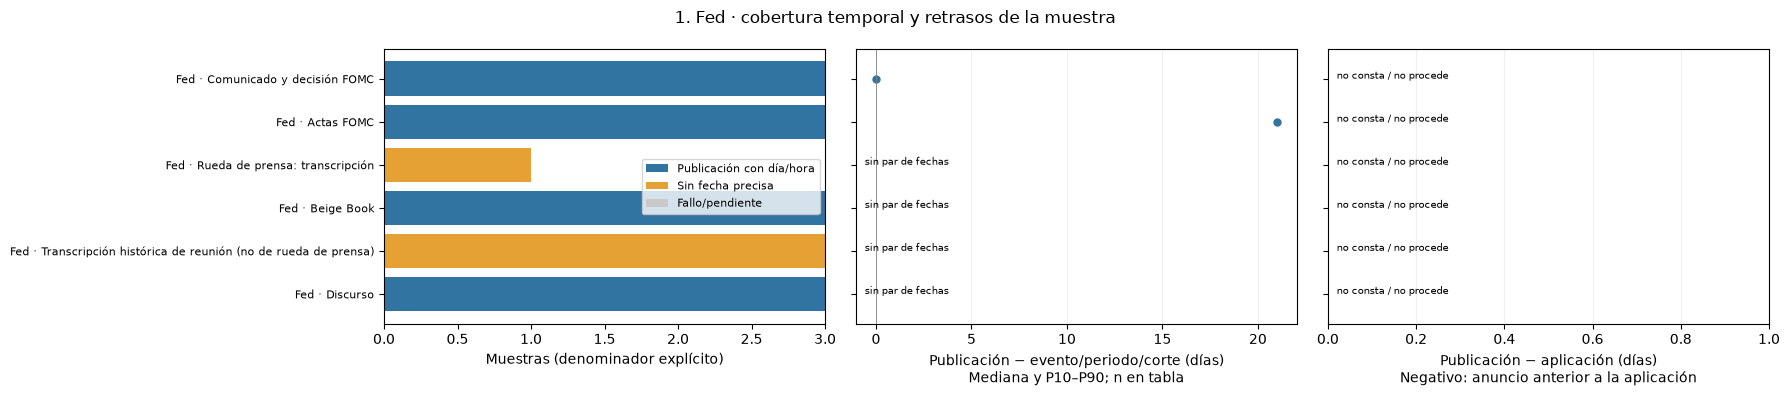

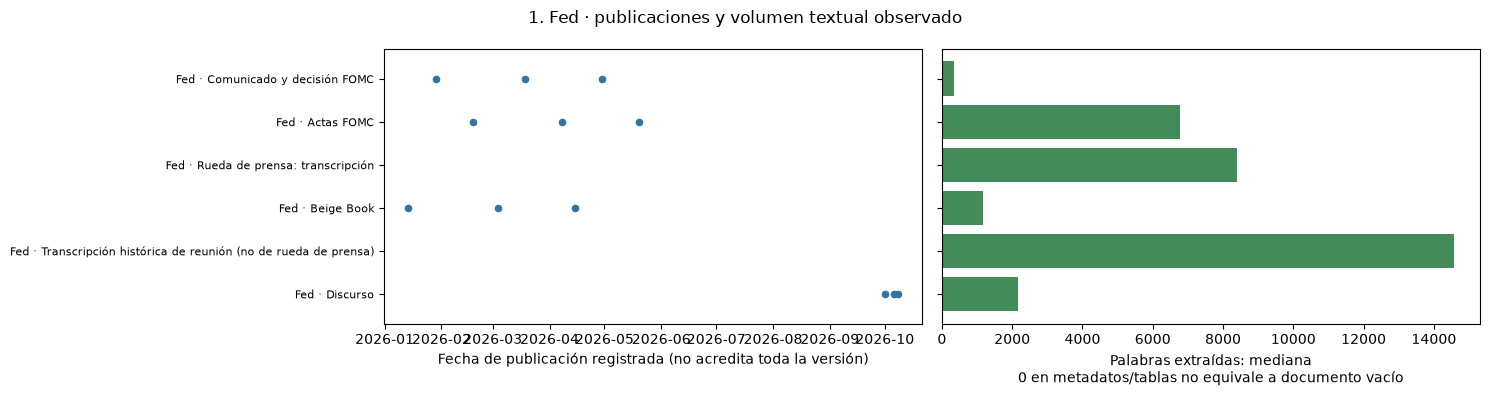

Ejemplo · Federal Reserve issues FOMC statement 
URL: https://www.federalreserve.gov/newsevents/pressreleases/monetary20260128a.htm 
Hash: cc76d9e77667482e3ee299ef0b2a4a74508643cd0078fa576dbd6cc6b795b6d0
January 28, 2026

Federal Reserve issues FOMC statement

For release at 2:00 p.m. EST Share

Available indicators suggest that economic activity has been expanding at a solid pace. Job gains have remained low, and the unemployment rate has shown some signs of stabilization. Inflation remains somewhat elevated.

The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run. Uncertainty about the economic outlook remains elevated. The Committee is attentive to the risks to both sides of its dual mandate.

In support of its goals, the Committee decided to maintain the target range for the federal funds rate at 3‑1/2 to 3‑3/4 percent. In considering the extent and timing of additional adjustments to the target range for the federal funds rate,

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,Fed,Comunicado y decisión FOMC,2026-03-18T14:00:00-04:00,0.102,cc76d9e77667482e3ee299ef0b2a4a74508643cd0078fa576dbd6cc6b795b6d0,1a2cc7b70cb2e1e403f2a13320fb73230707c074d017fa8a5aa590fe338534ca
1,Fed,Comunicado y decisión FOMC,2026-04-29T14:00:00-04:00,0.141,1a2cc7b70cb2e1e403f2a13320fb73230707c074d017fa8a5aa590fe338534ca,b7135ec05b24e31a3b521a6fa02dcced15c544e7f9814df419f9da3b3c4dc4f5
2,Fed,Actas FOMC,2026-04-08,0.455,592b71b09c300b031090a108e79964d0215c9461564d6ed1b85a2217bbece69b,85520f67fa9e473faed5f4af4bfd2999a3b6ebc376e298fdb8ec1c080bf4c844
3,Fed,Actas FOMC,2026-05-20,0.434,85520f67fa9e473faed5f4af4bfd2999a3b6ebc376e298fdb8ec1c080bf4c844,508c5bf45ef57c5f93d1bcf8438c3f735c48d0e1c6dd0201759cb1cb70c1a8df
4,Fed,Beige Book,2026-03-04,0.584,eacc0ff1f43668e67ca360572b467c4da0101b6e7f642ce50dbc8a7f82d78cd3,3f4403ce0a6dc07b2c08cd2648d8912036b1ca704d1f6432465121976b475eee
5,Fed,Beige Book,2026-04-15,0.577,3f4403ce0a6dc07b2c08cd2648d8912036b1ca704d1f6432465121976b475eee,261af2eb6e45b1244c6b981f96105feacb224e5e29da15337902203ffebf0cf2
6,Fed,Discurso,2026-10-06,0.781,3dbf3833f1aa105d66c2a34d3f417693139ea41d30e3fa26a9656d96c2be3e6b,6c59812b826612415661b60bd513697d7d75ecbb6b148ed6eae853af58b3736a
7,Fed,Discurso,2026-10-08,0.807,6c59812b826612415661b60bd513697d7d75ecbb6b148ed6eae853af58b3736a,b2a1623b77f9893891ff11ad2e3a392ab0fdc882300cb12584fcb690573ed69b


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [3]:
resumen_01 = mostrar_apartado(sonda, 1, '1. Fed')

## 2. BCE

<a id="bce"></a>

**Elección:** portal del BCE. Mantiene decisiones, comparecencias y deliberaciones como series distintas, evitando mezclar documentos de la misma reunión.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Decisiones de política monetaria | [Monetary policy decisions](https://www.ecb.europa.eu/press/govcdec/mopo/html/index.en.html) | Sí | Listados y texto HTML |
| Declaración y preguntas/respuestas | [Conferencias de prensa](https://www.ecb.europa.eu/press/press_conference/html/index.en.html) | Sí | HTML; separar declaración y cada Q&A |
| Accounts, equivalentes a actas resumidas | [Monetary policy accounts](https://www.ecb.europa.eu/press/accounts/html/index.en.html) | Sí | HTML con fecha de reunión y de publicación |
| Discursos | [Speeches](https://www.ecb.europa.eu/press/key/html/index.en.html) | Sí | HTML/PDF según documento |

**Calidad y tiempo:** guardar el idioma original y vincular traducciones como versiones relacionadas. Las accounts están disponibles después de la reunión; usar la fecha real de publicación, sin imponer “+28 días” a todas las ediciones. La fecha de reunión identifica el evento; la fecha de publicación decide cuándo podía conocerlo el pipeline.

### Sonda: adquisición y mediciones

**Medición específica.** Decisión, declaración, Q&A, accounts y discursos se mantienen separados. Las accounts identifican la reunión en el encabezado y la publicación en `ecb-publicationDate`; el gráfico usa ese par real. Las decisiones pueden indicar una aplicación futura. La sección Q&A hereda la publicación del padre, pero no acredita la fecha de subida de la transcripción ni sustituye el documento completo.

In [4]:
inventario_02 = sonda.inventario(2)
display(inventario_02[["fuente", "tipo", "adaptador"]])
muestra_02 = sonda.ejecutar(2)

,fuente,tipo,adaptador
0,BCE,Decisión de política monetaria,documento
1,BCE,Declaración de política monetaria,documento
2,BCE,Monetary policy accounts,documento
3,BCE,Discurso,documento
4,BCE,Preguntas y respuestas,qa


7 intentos · 7 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BCE,Decisión de política monetaria,1,1,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,0,0,NaN,NaN,NaN,-6.0,602.0,1,0,0.11
1,BCE,Declaración de política monetaria,1,1,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,5952.0,1,0,0.14
2,BCE,Monetary policy accounts,3,3,2026-07-09 00:00:00+00:00,2026-10-08 00:00:00+00:00,0,3,28.0,28.0,33.6,NaN,10323.0,3,0,0.52
3,BCE,Discurso,1,1,2026-09-09 00:00:00+00:00,2026-09-09 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1027.0,1,0,0.11
4,BCE,Preguntas y respuestas,1,1,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,4005.0,0,0,0.14


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BCE,Decisión de política monetaria,OK,NaN,2026-09-10,día,2026-09-16,NaN,-6.0,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260910~314e508016.en.html
1,BCE,Declaración de política monetaria,OK,NaN,2026-09-10,día,NaN,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is26091...
2,BCE,Monetary policy accounts,OK,2026-09-10,2026-10-08,día,NaN,28.0,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/accounts/2026/html/ecb.mg261008~a10153d090.en.html
3,BCE,Monetary policy accounts,OK,2026-07-23,2026-08-27,día,NaN,35.0,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/accounts/2026/html/ecb.mg260827~f06c21fd54.en.html
4,BCE,Monetary policy accounts,OK,2026-06-11,2026-07-09,día,NaN,28.0,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/accounts/2026/html/ecb.mg260709~0e7f8241c9.en.html
5,BCE,Discurso,OK,NaN,2026-09-09,día,NaN,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/key/date/2026/html/ecb.sp260909~59a07e6f05.en.html
6,BCE,Preguntas y respuestas,OK,NaN,2026-09-10,día,NaN,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/press_conference/monetary-policy-statement/2026/html/ecb.is26091...


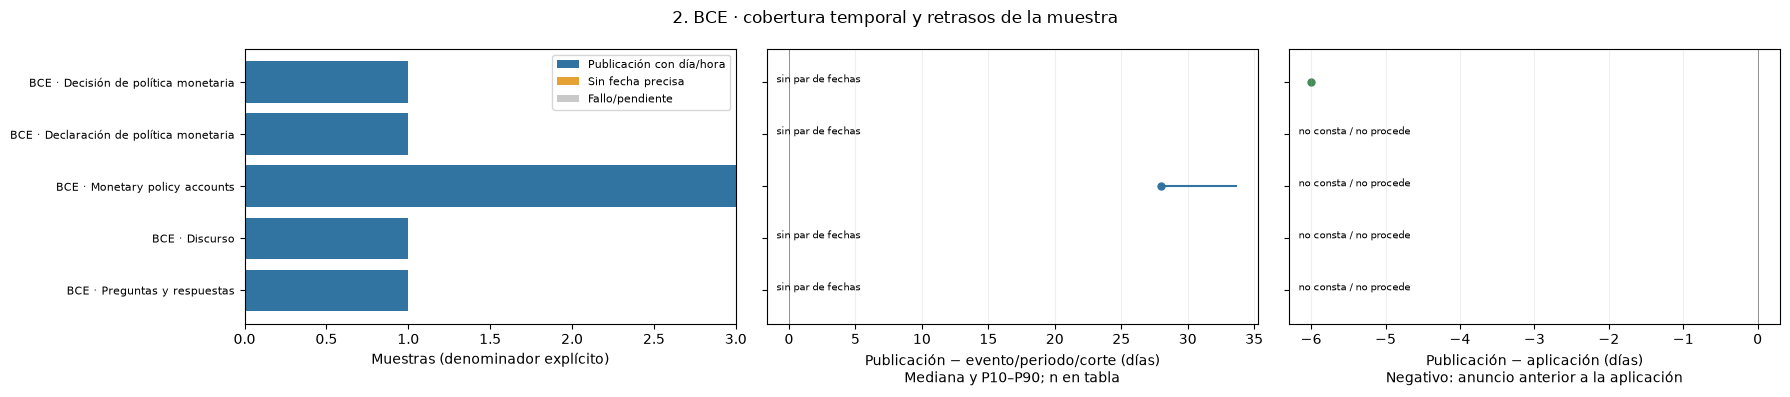

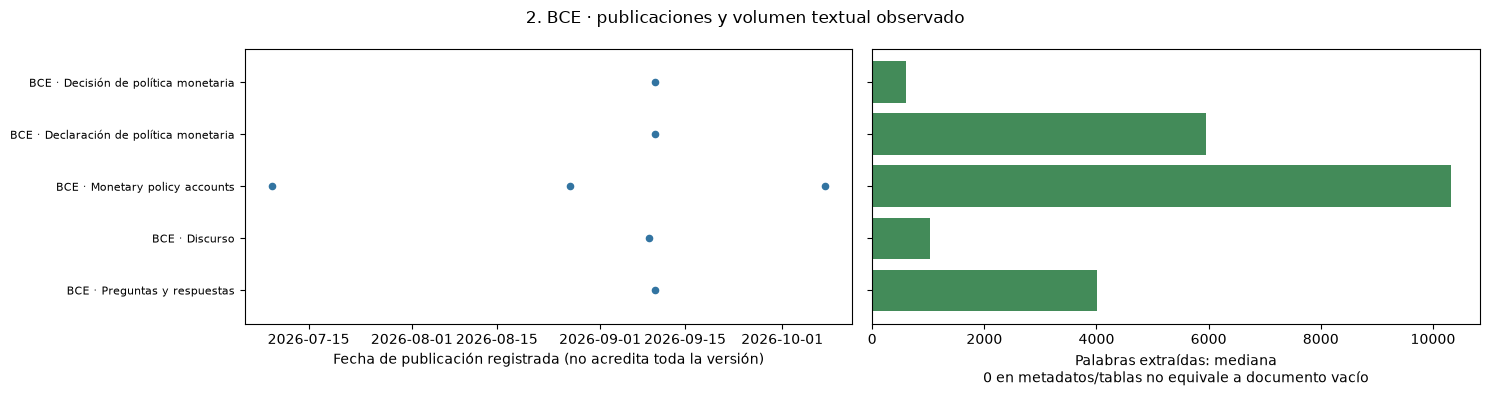

Ejemplo · Monetary policy decisions 
URL: https://www.ecb.europa.eu/press/pr/date/2026/html/ecb.mp260910~314e508016.en.html 
Hash: fdc4b15cefd0d6d43cef0573f95528db8281fefb5ef567ae994fdd6addc5f013
PRESS RELEASE

Monetary policy decisions

10 September 2026

The Governing Council today decided to raise the three key ECB interest rates by 25 basis points. The conflict in the Middle East continues to generate inflation pressures, and inflation is set to remain well above target for an extended period. Today’s decision underscores the Governing Council’s commitment to setting monetary policy to ensure that inflation stabilises at its 2% target in the medium term.

The baseline of the new ECB staff projections sees headline inflation averaging 3.0% in 2026, 2.5% in 2027 and 2.1% in 2028. For inflation excluding energy and food, the baseline foresees 2.5% in 2026, 2.6% in 2027 and 2.3% in 2028. Compared with June, the baseline projection for inflation in 2026 is unchanged, while it has been r

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,BCE,Monetary policy accounts,2026-08-27,0.495,fa7e45262d2a42e75cf889e7bb4260f0e32f4fbefb37e898039fcdc82229dfb3,2d19213f5193859d997966df1d4a61f445e7989abf484380bb7fb56890f557a6
1,BCE,Monetary policy accounts,2026-10-08,0.485,2d19213f5193859d997966df1d4a61f445e7989abf484380bb7fb56890f557a6,0df4389f031633deeeee352695bddc138752fb0f5af0aa326c2c733ae5268175


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [5]:
resumen_02 = mostrar_apartado(sonda, 2, '2. BCE')

## 3. BoE y BoJ

<a id="boe-boj"></a>

**Elección:** Bank of England y Bank of Japan, respectivamente. Para análisis textual, sus informes y actas completos tienen más valor que un resumen de prensa externo.

| Banco e información | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| BoE: decisión y actas MPC | [Última decisión y enlaces a documentos](https://www.bankofengland.co.uk/monetary-policy/the-interest-rate-bank-rate); [ejemplo publicado: julio de 2026](https://www.bankofengland.co.uk/monetary-policy-summary-and-minutes/2026/july-2026) | Sí | HTML/PDF; descubrir ediciones desde enlaces oficiales |
| BoE: Monetary Policy Report | [Archivo MPR](https://www.bankofengland.co.uk/sitemap/monetary-policy-report) | Sí | Informes HTML/PDF por edición |
| BoE: discursos | [Speeches](https://www.bankofengland.co.uk/news/speeches) | Sí | HTML y documentos enlazados |
| BoJ: comunicados, opiniones y actas | [Calendario y documentos de reuniones](https://www.boj.or.jp/en/mopo/mpmsche_minu/index.htm) | Sí | Enlaces a declaraciones, Summary of Opinions y Minutes |
| BoJ: informes de perspectivas | [Outlook Report](https://www.boj.or.jp/en/mopo/outlook/index.htm) | Sí | PDF de informes y perspectivas |
| BoJ: discursos incluidos en BIS | [Discursos de bancos centrales BIS](https://www.bis.org/speeches/central-bank) | Sí | Complemento; contrastar con el original del BoJ |

**Calidad y tiempo:** en BoJ, las opiniones y las actas son documentos diferentes. Su [explicación oficial del procedimiento](https://www.boj.or.jp/en/about/education/oshiete/seisaku/b20.htm) vincula la publicación de actas a su aprobación en una reunión posterior. El “+44 días” de la captura no debe convertirse en retraso fijo. Las traducciones al inglés pueden aparecer después del original japonés.

### Sonda: adquisición y mediciones

**Medición específica.** BoE y BoJ conservan filas distintas. En BoJ se leen por separado las columnas **Date of MPM** y **Release Schedule** del calendario: Summary of Opinions y Minutes pueden salir en días distintos. No se interpreta la fecha de reunión codificada en el nombre del PDF como publicación. La fecha del texto inglés no se presume idéntica a la del original japonés.

In [6]:
inventario_03 = sonda.inventario(3)
display(inventario_03[["fuente", "tipo", "adaptador"]])
muestra_03 = sonda.ejecutar(3)

,fuente,tipo,adaptador
0,BoE,Decisión y actas MPC,documento
1,BoE,Monetary Policy Report,documento
2,BoE,Discurso,documento
3,BoJ,Comunicado de política monetaria,documento
4,BoJ,Summary of Opinions,documento
5,BoJ,Minutes,documento
6,BoJ,Outlook Report,documento
7,BoJ,Discurso original BoJ,documento


18 intentos · 18 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BoE,Decisión y actas MPC,1,1,2026-07-30 00:00:00+00:00,2026-07-30 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,4078.0,1,0,0.10
1,BoE,Monetary Policy Report,1,1,2026-04-30 00:00:00+00:00,2026-04-30 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,27980.0,1,0,4.73
2,BoE,Discurso,1,1,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1340.0,1,0,0.08
3,BoJ,Comunicado de política monetaria,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,441.0,3,0,0.40
4,BoJ,Summary of Opinions,3,3,2026-02-02 00:00:00+00:00,2026-05-12 00:00:00+00:00,0,3,10.2,11.0,13.4,NaN,2097.0,3,0,0.60
5,BoJ,Minutes,3,3,2026-03-25 00:00:00+00:00,2026-06-19 00:00:00+00:00,0,3,49.6,52.0,59.2,NaN,10416.0,3,0,0.91
6,BoJ,Outlook Report,3,3,2026-01-26 00:00:00+00:00,2026-08-03 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,15225.0,0,0,3.95
7,BoJ,Discurso original BoJ,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,4392.0,3,0,0.19


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BoE,Decisión y actas MPC,OK,NaN,2026-07-30,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/monetary-policy-summary-and-minutes/2026/july-2026
1,BoE,Monetary Policy Report,OK,NaN,2026-04-30,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/monetary-policy-report/2026/april-2026
2,BoE,Discurso,OK,NaN,2026-10-08,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/speech/2026/october/andrew-bailey-speech-at-the-istanbul-economi...
3,BoJ,Comunicado de política monetaria,OK,2026-01-23,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.boj.or.jp/en/mopo/mpmdeci/mpr_2026/k260123a.pdf
4,BoJ,Comunicado de política monetaria,OK,2026-03-19,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.boj.or.jp/en/mopo/mpmdeci/mpr_2026/k260319a.pdf
5,BoJ,Comunicado de política monetaria,OK,2026-04-28,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.boj.or.jp/en/mopo/mpmdeci/mpr_2026/k260428a.pdf
6,BoJ,Summary of Opinions,OK,2026-01-23,2026-02-02,día,None,10.0,NaN,"aviso PDF: Not to be released until 8:50 a.m. Japan Standard Time on Monday, February 2, 2026",pendiente_versión,https://www.boj.or.jp/en/mopo/mpmsche_minu/opinion_2026/opi260123.pdf
7,BoJ,Summary of Opinions,OK,2026-03-19,2026-03-30,día,None,11.0,NaN,"aviso PDF: Not to be released until 8:50 a.m. Japan Standard Time on Monday, March 30, 2026",pendiente_versión,https://www.boj.or.jp/en/mopo/mpmsche_minu/opinion_2026/opi260319.pdf
8,BoJ,Summary of Opinions,OK,2026-04-28,2026-05-12,día,None,14.0,NaN,"aviso PDF: Not to be released until 8:50 a.m. Japan Standard Time on Tuesday, May 12, 2026",pendiente_versión,https://www.boj.or.jp/en/mopo/mpmsche_minu/opinion_2026/opi260428.pdf
9,BoJ,Minutes,OK,2026-01-23,2026-03-25,día,None,61.0,NaN,"aviso PDF: Not to be released until 8:50 a.m. Japan Standard Time on Wednesday, March 25, 2026",pendiente_versión,https://www.boj.or.jp/en/mopo/mpmsche_minu/minu_2026/g260123.pdf


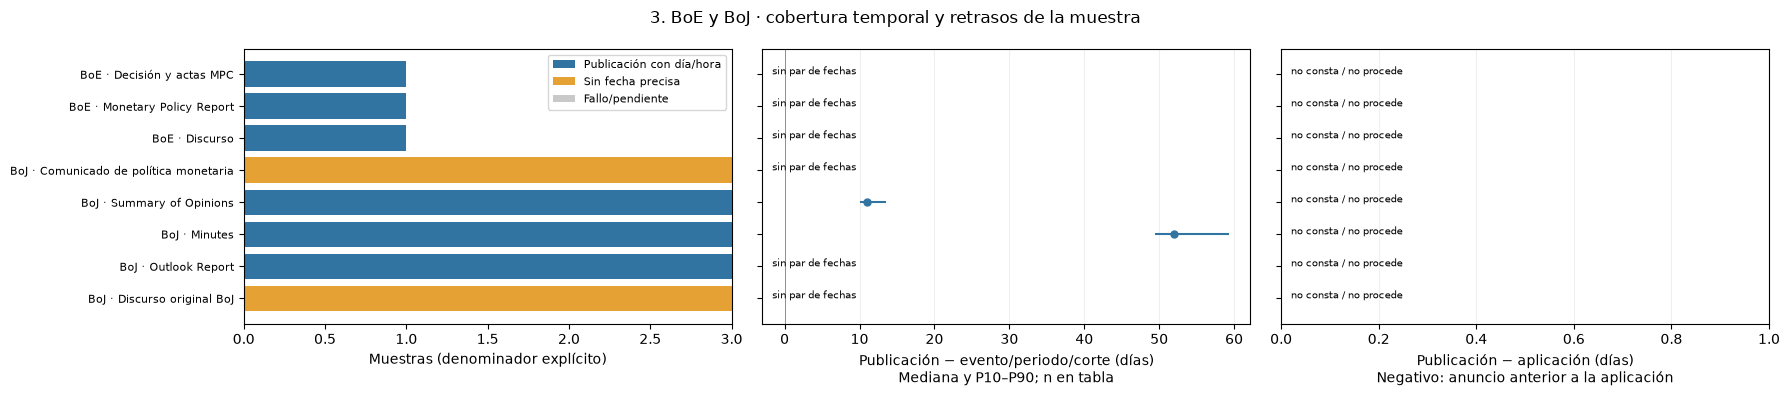

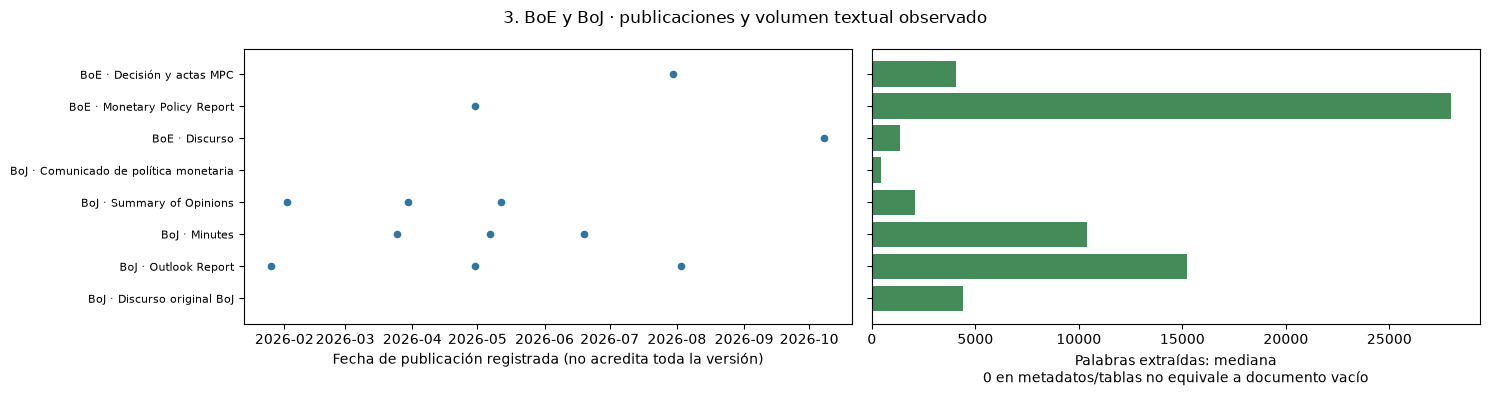

Ejemplo · Bank Rate maintained at 3.75% - July 2026 Monetary Policy Summary and Minutes 
URL: https://www.bankofengland.co.uk/monetary-policy-summary-and-minutes/2026/july-2026 
Hash: a5a7f617975401ddc5a75cb95dc2cf453ba23e425182f101d7c372e851924faf
Bank Rate maintained at 3.75% - July 2026 Monetary Policy Summary and Minutes

Related links Related links Our latest decision explained Monetary Policy Report - July 2026

Monetary Policy Summary, July 2026

At its meeting ending on 29 July 2026, the Monetary Policy Committee (MPC) voted by a majority of 6–3 to maintain Bank Rate at 3.75%. Three members voted to increase Bank Rate by 0.25 percentage points, to 4%.

In response to events in the Middle East, crude and refined energy prices have remained volatile and higher than pre-conflict. The impact of the energy shock on the UK economy remains uncertain. Monetary policy cannot influence energy prices but is being set to ensure that the economic adjustment to them occurs in a way that achi

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,BoJ,Summary of Opinions,2026-03-30,0.581,329850439e82e56644a8df21322fb6c971488bbd80cbfd54c8f1c112ce04e404,52b67b48bce564dff3a5982f75952f98eb0c63c2d3951b4d434941b16c554846
1,BoJ,Summary of Opinions,2026-05-12,0.570,52b67b48bce564dff3a5982f75952f98eb0c63c2d3951b4d434941b16c554846,2733cf679f4c190d849975bd183a1ca479d0d0a2056308da5067882e91d1e8d8
2,BoJ,Minutes,2026-05-07,0.473,0f02994dcb169828c4a1300af009fe2b4a3330cb0914eb8cd5c41bb51a0e730e,86f599e71a92ccb3849b6e06bd9b06673ba82cd6cc6e1809d42b861d35d30d2f
3,BoJ,Minutes,2026-06-19,0.462,86f599e71a92ccb3849b6e06bd9b06673ba82cd6cc6e1809d42b861d35d30d2f,e4b6655fc75bff14ef7a1a945e49561d841d893ccd3bce5a124f23d3c9361e4d


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [7]:
resumen_03 = mostrar_apartado(sonda, 3, '3. BoE y BoJ')

## 4. Discursos BIS y Annual Report

<a id="discursos-bis"></a>

**Elección para un corpus internacional:** descarga oficial del BIS. Para el texto definitivo de un discurso concreto, contrastar con el banco emisor si hay discrepancias.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Discursos de bancos centrales | [Descarga oficial de discursos BIS](https://www.bis.org/speeches/central-bank/download) | Sí, sin cuenta; paquete para uso no comercial según sus condiciones | Archivos CSV UTF-8 comprimidos, por año o conjunto, desde 1996 |
| Documento individual y metadatos | [Catálogo BIS](https://www.bis.org/speeches/central-bank) | Sí | Página y documento enlazado |
| Informe económico anual | [Annual Economic Report](https://www.bis.org/publications/aer) | Sí | Capítulos e informe completo |
| Informe institucional anual | [Annual Report](https://www.bis.org/about/areport/index.htm) | Sí | Informe de actividad institucional |

**Calidad:** el paquete es especialmente útil para empezar sin reconstruir miles de páginas. BIS advierte que la cobertura no es exhaustiva y que la conversión automática puede introducir errores. Validar muestras contra los originales y guardar la fecha/versión de la descarga. Annual Economic Report y Annual Report tienen objetivos diferentes: catalogarlos por separado. No asumir que todas las publicaciones BIS comparten la licencia del paquete de discursos.

### Sonda: adquisición y mediciones

**Medición específica.** El discurso individual, el paquete CSV de 1996, el Annual Economic Report y el Annual Report institucional tienen registros propios. La fecha de un discurso es un evento; la fecha de subida al BIS o de creación del paquete es otra. El CSV conserva sus nombres de campos y no entra en TimeGate hasta contrastar originales y versiones.

In [8]:
inventario_04 = sonda.inventario(4)
display(inventario_04[["fuente", "tipo", "adaptador"]])
muestra_04 = sonda.ejecutar(4)

,fuente,tipo,adaptador
0,BIS,Discurso individual y metadatos,documento
1,BIS,Annual Economic Report,documento
2,BIS,Annual Report institucional,documento
3,BIS,CSV oficial de discursos (1996),bis_csv


10 intentos · 10 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BIS,Discurso individual y metadatos,3,3,2026-10-13 00:00:00+00:00,2026-10-14 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1582.0,3,0,0.40
1,BIS,Annual Economic Report,3,3,2024-06-30 00:00:00+00:00,2026-06-28 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,274.0,3,0,0.42
2,BIS,Annual Report institucional,3,3,2024-06-30 00:00:00+00:00,2026-06-28 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1151.0,3,0,0.45
3,BIS,CSV oficial de discursos (1996),1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.07


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BIS,Discurso individual y metadatos,OK,None,2026-10-14,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/speeches/20261014-closing-remarks-conference-main-findings-portugals-financi...
1,BIS,Discurso individual y metadatos,OK,None,2026-10-13,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/speeches/20261013-cross-border-payments-necessity-africas-resilience-and-eco...
2,BIS,Discurso individual y metadatos,OK,None,2026-10-13,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/speeches/20261013-leveraging-mauritius-ifc-payment-system-hub
3,BIS,Annual Economic Report,OK,None,2026-06-28,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/aer-2026
4,BIS,Annual Economic Report,OK,None,2025-06-29,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/aer-2025
5,BIS,Annual Economic Report,OK,None,2024-06-30,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/aer-2024
6,BIS,Annual Report institucional,OK,None,2026-06-28,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/annual-report-2026
7,BIS,Annual Report institucional,OK,None,2025-06-29,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/annual-report-2025
8,BIS,Annual Report institucional,OK,None,2024-06-30,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/annual-report-2024
9,BIS,CSV oficial de discursos (1996),OK,None,NaN,desconocida,None,NaN,NaN,Fecha del discurso y publicación del paquete son distintas; pendiente de contraste,sin_fecha,https://www.bis.org/pages/download-central-bankers-speeches/speeches-1996.zip


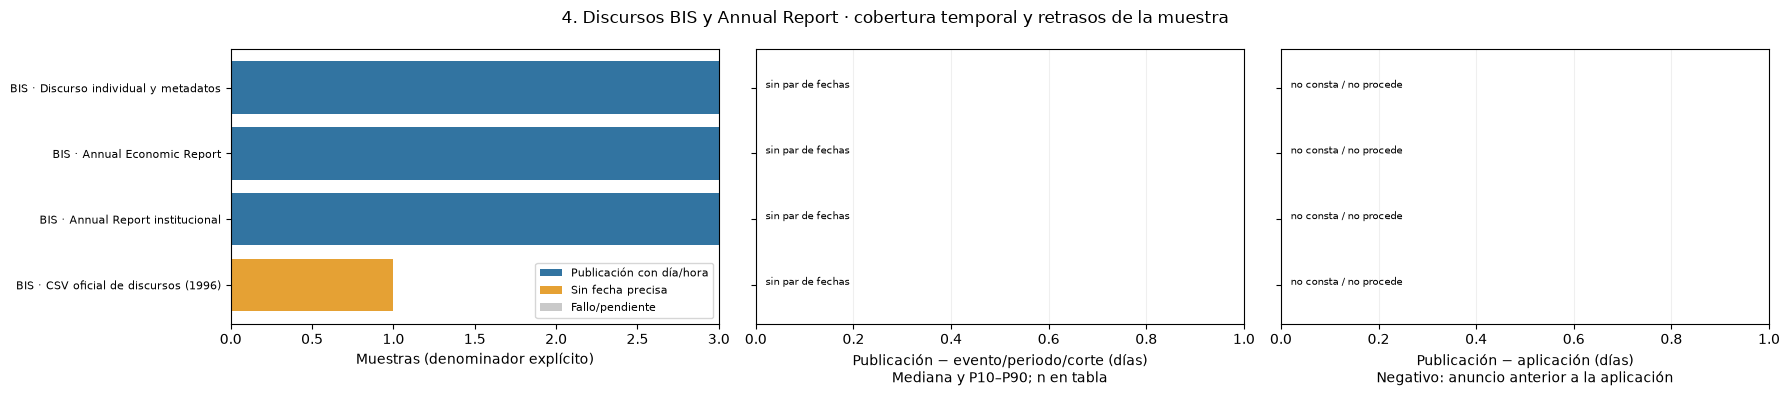

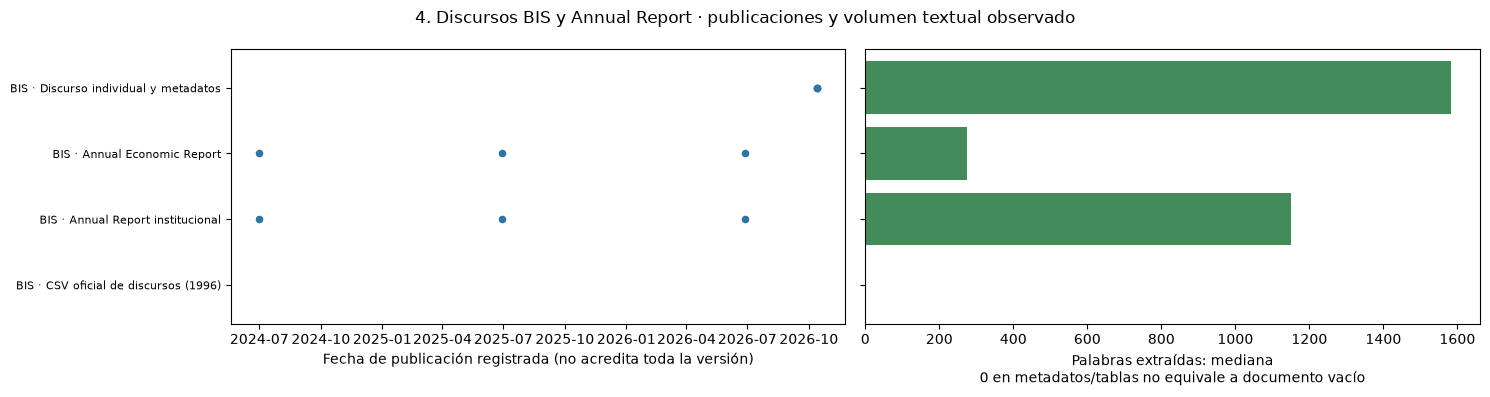

Ejemplo · Closing remarks - Conference on the Main Findings of Portugal's Financial Sector Assessment Program 
URL: https://www.bis.org/speeches/20261014-closing-remarks-conference-main-findings-portugals-financial-sector-assessment-program 
Hash: 1fffce69c4f99c0b11ec45ca8ba1314c5e8163325f562583724f25f997b69060
Closing remarks - Conference on the Main Findings of Portugal's Financial Sector Assessment Program

It is my pleasure to deliver the closing remarks for this event.

As we come to the end of this conference, I would like to begin by thanking our moderators, speakers and participants for such engaging and insightful discussions.

I would also like to reiterate our appreciation to the IMF for the work carried out during this FSAP and for the constructive dialogue maintained throughout the process.

And thank the outstanding work undertaken by the staff at the Bank of Portugal.

Throughout the afternoon, we reflected on two key aspects of the Portuguese financial stability framewo

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,BIS,Discurso individual y metadatos,2026-10-13,0.768,f775917d6689d101c1ad999ded02806153de0b64d283694014881f99f90d2462,10c00911c3a7900ba346d40bb01e0a7ebd3f0eb6adc78e443ecf46ca601378ae
1,BIS,Discurso individual y metadatos,2026-10-14,0.824,10c00911c3a7900ba346d40bb01e0a7ebd3f0eb6adc78e443ecf46ca601378ae,1fffce69c4f99c0b11ec45ca8ba1314c5e8163325f562583724f25f997b69060
2,BIS,Annual Economic Report,2025-06-29,0.786,d4896d9e5c42579ab43ff6c7fc9ad5b0d5003efeb6d2ff0e951ae17d8e76e2cf,f99e992d6ca576b0869b971dc55a404e1e8fed5bfa512f4047e1c99d8edbf3cb
3,BIS,Annual Economic Report,2026-06-28,0.810,f99e992d6ca576b0869b971dc55a404e1e8fed5bfa512f4047e1c99d8edbf3cb,c025d43c921f9402050b20fc052ab434177d552e33883223ce8c2081b23bdcdd
4,BIS,Annual Report institucional,2025-06-29,0.616,b1f2bf7e4fec1de6b658bc0505bc2cf65c5478244e47067801f77ae72937036f,8ed6607b0a905a37c186c78edabdeebf5cfe4c41b4569b88a1adc81f21936415
5,BIS,Annual Report institucional,2026-06-28,0.586,8ed6607b0a905a37c186c78edabdeebf5cfe4c41b4569b88a1adc81f21936415,79500a0748cdf33ddd6aa75358576bf6460ed16c5741f10afa62c62af9e3fe50


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [9]:
resumen_04 = mostrar_apartado(sonda, 4, '4. Discursos BIS y Annual Report')

## 5. Otros bancos centrales

<a id="otros-bancos"></a>

**Elección:** emisor original para decisiones, actas, informes y discursos. Las publicaciones digitales públicas indicadas son la primera ruta gratuita; no se ha probado todavía una descarga masiva de cada banco.

| Banco | Punto de entrada oficial | Información que buscar | Gratuidad y acceso |
|---|---|---|---|
| BCB, Brasil | [Comunicados Copom](https://www.bcb.gov.br/en/monetarypolicy/copomstatements/cronologicos) | Decisiones; localizar también actas e informes | Comunicados gratuitos; conservar original portugués cuando corresponda |
| BoC, Canadá | [Monetary policy](https://www.bankofcanada.ca/core-functions/monetary-policy/) | Decisiones, MPR, deliberaciones y discursos | Publicaciones gratuitas; HTML/PDF |
| SNB, Suiza | [Monetary policy decisions](https://www.snb.ch/en/the-snb/mandates-goals/monetary-policy/decisions) | Evaluaciones y decisiones monetarias | Gratuitas; documentos por evaluación |
| Riksbank, Suecia | [Monetary policy](https://www.riksbank.se/en-gb/monetary-policy/) | Decisiones, actas e informes | Gratuitas; HTML/PDF |
| Norges Bank, Noruega | [Monetary policy](https://www.norges-bank.no/en/topics/Monetary-policy/) | Decisiones, informes y discursos | Gratuitas; HTML/PDF |
| RBNZ, Nueva Zelanda | [Monetary policy](https://www.rbnz.govt.nz/monetary-policy) | Statements y decisiones del comité | Publicaciones gratuitas; archivos por edición |
| RBI, India | [Portal oficial](https://www.rbi.org.in/) | Press Releases, MPC, Speeches y Reports | Seleccionar documentos públicos gratuitos; no confundir con publicaciones ofrecidas por suscripción |
| Banxico, México | [Anuncios de decisiones](https://www.banxico.org.mx/publicaciones-y-prensa/anuncios-de-las-decisiones-de-politica-monetaria/anuncios-politica-monetaria-t.html) | Anuncios; localizar minutas e informes relacionados | Anuncios gratuitos; PDF |
| Banco de España | [Publicaciones](https://www.bde.es/wbe/es/publicaciones/) | Proyecciones, análisis y estabilidad financiera | Gratuitas; HTML/PDF |
| RBA, Australia | [Monetary policy](https://www.rba.gov.au/monetary-policy/) | Decisiones, actas e informes monetarios | Gratuitas; HTML/PDF |
| PBoC, China | [Portal inglés](https://www.pbc.gov.cn/en/); [ejemplo de informe publicado](https://www.pbc.gov.cn/en/3688229/3688353/3688362/5385746/index.html) | Monetary Policy Reports y comunicaciones | Ejemplo de acceso público; cobertura y automatización por comprobar |

**Calidad:** registrar país, institución, idioma y tipo de documento. Banco de España pertenece al Eurosistema: las decisiones monetarias del euro se obtienen del BCE; una traducción o republicación no es una decisión adicional. Para discursos internacionales, BIS es una alternativa gratuita útil, con cobertura parcial. Preferir descargas o feeds oficialmente ofrecidos antes de desarrollar extracción de páginas; no presuponer que todos ofrecen JSON/RSS/API.

### Sonda: adquisición y mediciones

**Medición específica.** Cada banco y cada tipo conserva su propia fila en tablas y gráficos. Se consulta la edición o el listado indicado; el modo ampliado no reconstruye todo el archivo de esos bancos. Un PDF sin fecha explícita, un portal JavaScript o un bloqueo HTTP queda pendiente, sin inventar retrasos comunes. Banco de España se mantiene como fuente de análisis del Eurosistema; sus documentos no se cuentan como otra decisión monetaria del BCE.

In [10]:
inventario_05 = sonda.inventario(5)
display(inventario_05[["fuente", "tipo", "adaptador"]])
muestra_05 = sonda.ejecutar(5)

,fuente,tipo,adaptador
0,BCB (Brasil),Comunicado Copom,documento
1,BCB (Brasil),Acta Copom,documento
2,BCB (Brasil),Monetary Policy Report,documento
3,BoC (Canadá),Decisión monetaria,documento
4,BoC (Canadá),Monetary Policy Report,documento
5,BoC (Canadá),Deliberaciones,documento
6,BoC (Canadá),Discurso,documento
7,SNB (Suiza),Evaluación y decisión monetaria,documento
8,Riksbank (Suecia),Decisión monetaria,documento
9,Riksbank (Suecia),Actas,documento


47 intentos · 42 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BCB (Brasil),Comunicado Copom,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
1,BCB (Brasil),Acta Copom,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,3256.0,1,0,0.31
2,BCB (Brasil),Monetary Policy Report,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,20613.0,0,0,12.73
3,BoC (Canadá),Decisión monetaria,1,1,2026-09-02 00:00:00+00:00,2026-09-02 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,638.0,1,0,0.14
4,BoC (Canadá),Monetary Policy Report,1,1,2026-07-15 00:00:00+00:00,2026-07-15 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,364.0,1,0,0.16
5,BoC (Canadá),Deliberaciones,1,1,2026-09-16 00:00:00+00:00,2026-09-16 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1763.0,1,0,0.14
6,BoC (Canadá),Discurso,1,1,2026-09-21 00:00:00+00:00,2026-09-21 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,447.0,1,0,0.14
7,SNB (Suiza),Evaluación y decisión monetaria,1,1,2026-06-18 00:00:00+00:00,2026-06-18 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,739.0,1,0,0.12
8,Riksbank (Suecia),Decisión monetaria,3,3,2026-06-17 00:00:00+00:00,2026-09-24 00:00:00+00:00,0,3,1.0,1.0,1.0,-6.0,324.0,3,0,1.89
9,Riksbank (Suecia),Actas,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,8577.0,3,0,1.32


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BCB (Brasil),Comunicado Copom,PENDIENTE,NaN,NaN,desconocida,NaN,NaN,NaN,,sin_muestra,https://www.bcb.gov.br/en/monetarypolicy/copomstatements/cronologicos
1,BCB (Brasil),Acta Copom,OK,NaN,NaN,desconocida,NaN,NaN,NaN,NaN,sin_fecha,https://www.bcb.gov.br/content/copom/atascopom/Copom262-not20240508262.pdf
2,BCB (Brasil),Monetary Policy Report,OK,NaN,NaN,desconocida,NaN,NaN,NaN,NaN,sin_fecha,https://www.bcb.gov.br/content/ri/inflationreport/202503/rpm202503i.pdf
3,BoC (Canadá),Decisión monetaria,OK,NaN,2026-09-02,día,NaN,NaN,NaN,meta publication_date,pendiente_versión,https://www.bankofcanada.ca/2026/09/fad-press-release-2026-09-02/
4,BoC (Canadá),Monetary Policy Report,OK,NaN,2026-07-15,día,NaN,NaN,NaN,meta publication_date,pendiente_versión,https://www.bankofcanada.ca/publications/mpr/mpr-2026-07-15/
5,BoC (Canadá),Deliberaciones,OK,NaN,2026-09-16,día,NaN,NaN,NaN,meta publication_date,pendiente_versión,https://www.bankofcanada.ca/2026/09/summary-of-governing-council-deliberations-fixed-announcemen...
6,BoC (Canadá),Discurso,OK,NaN,2026-09-21,día,NaN,NaN,NaN,meta publication_date,pendiente_versión,https://www.bankofcanada.ca/2026/09/adapting-structural-forces-navigating-uncertainty/
7,SNB (Suiza),Evaluación y decisión monetaria,OK,NaN,2026-06-18,día,NaN,NaN,NaN,fecha visible .cms-stage__date,pendiente_versión,https://www.snb.ch/en/publications/communication/press-releases-restricted/pre_20260618
8,Riksbank (Suecia),Decisión monetaria,OK,2026-09-23,2026-09-24,día,2026-09-30,1.0,-6.0,etiqueta published on 24 September 2026,pendiente_versión,https://www.riksbank.se/en-gb/monetary-policy/monetary-policy-report/2026/monetary-policy-decisi...
9,Riksbank (Suecia),Decisión monetaria,OK,2026-08-19,2026-08-20,día,2026-08-26,1.0,-6.0,etiqueta Published 20 August 2026,pendiente_versión,https://www.riksbank.se/en-gb/monetary-policy/monetary-policy-report/2026/monetary-policy-decisi...


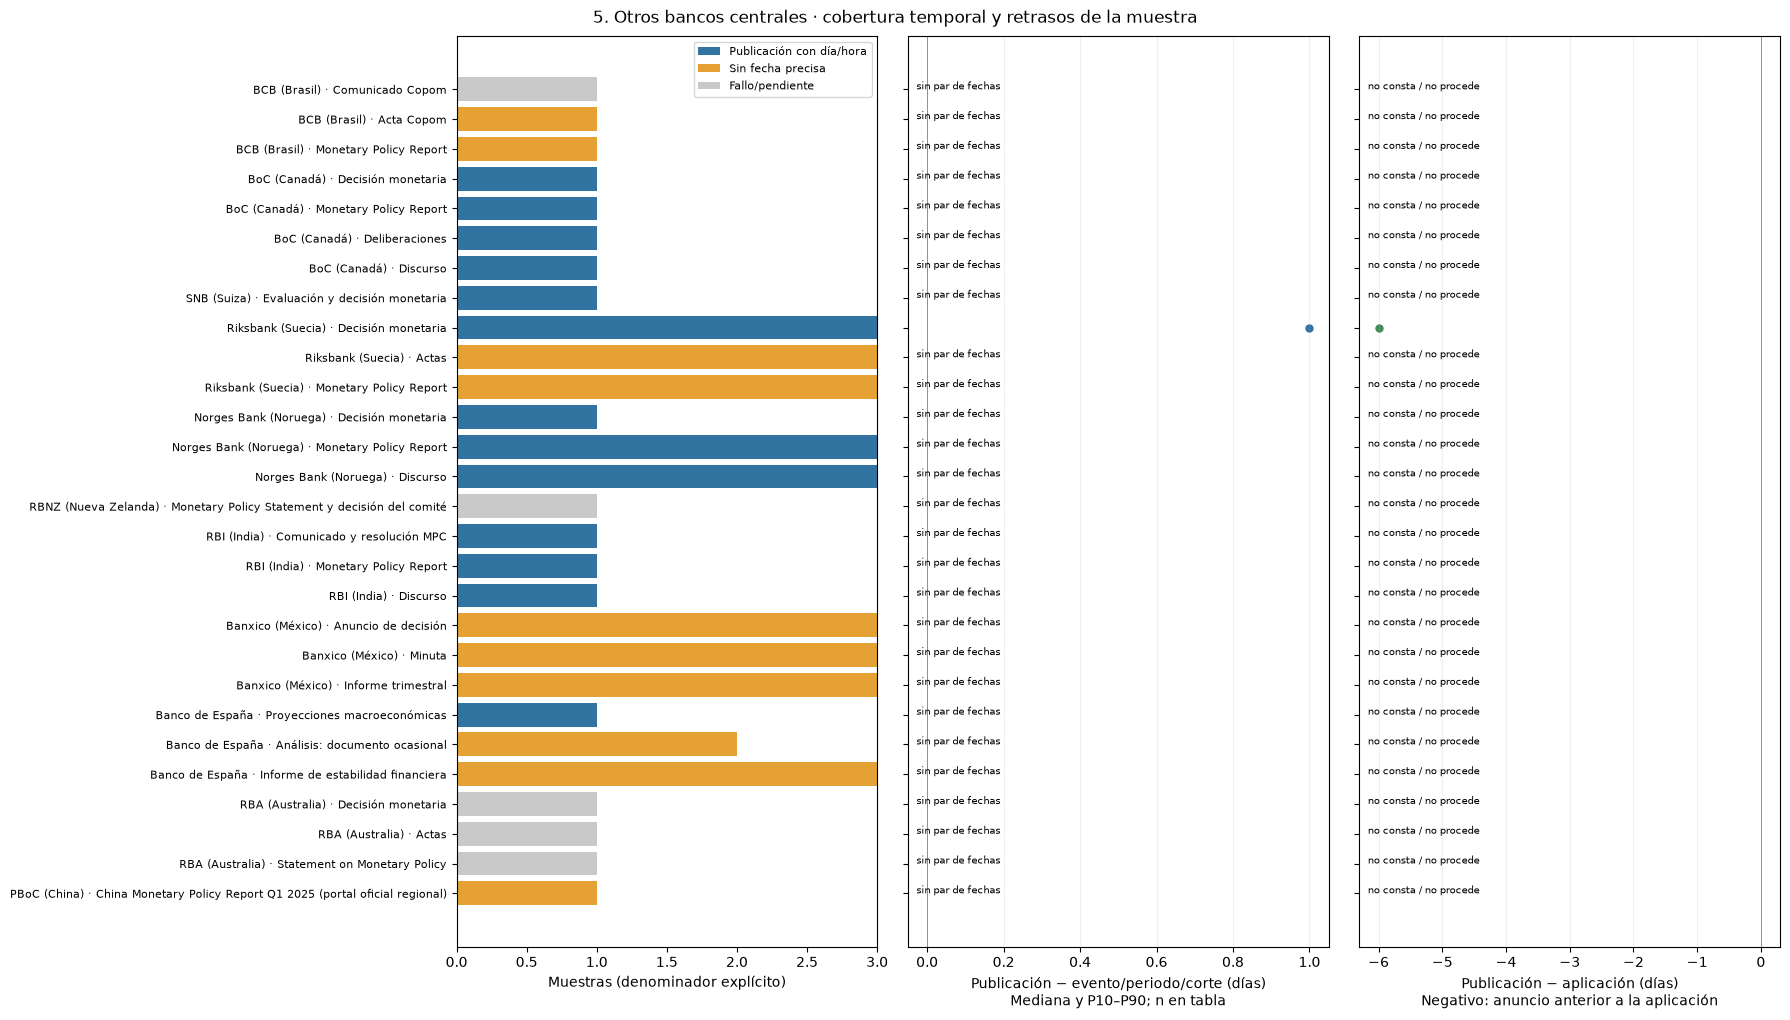

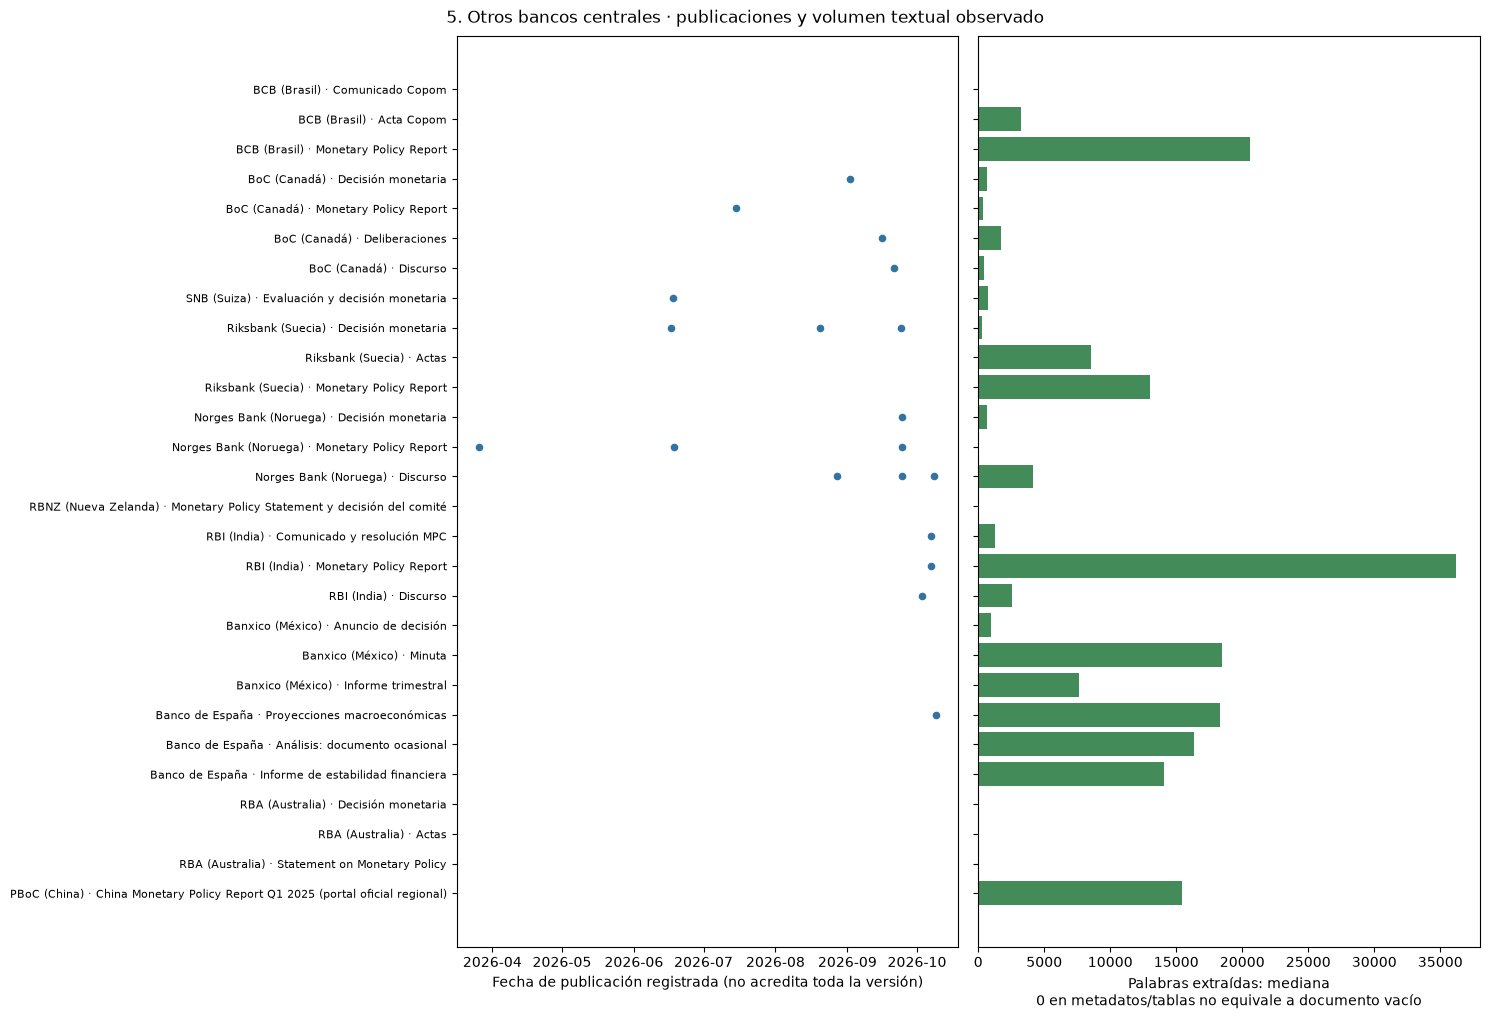

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
0,BCB (Brasil),Comunicado Copom,PENDIENTE,No se encontró un enlace con patrón '/copomstatements/[^/?#]+$',https://www.bcb.gov.br/en/monetarypolicy/copomstatements/cronologicos
24,RBNZ (Nueva Zelanda),Monetary Policy Statement y decisión del comité,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.rbnz.govt.nz/hub/publications/monetary-policy-statement/2025/nov-1125/monetary-polic...
43,RBA (Australia),Decisión monetaria,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.rba.gov.au/monetary-policy/int-rate-decisions/2026/
44,RBA (Australia),Actas,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.rba.gov.au/monetary-policy/rba-board-minutes/2026/
45,RBA (Australia),Statement on Monetary Policy,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.rba.gov.au/publications/smp/


Ejemplo · Acta Copom 
URL: https://www.bcb.gov.br/content/copom/atascopom/Copom262-not20240508262.pdf 
Hash: 543d43ee0264b4b821b6954613eed3ef9e9bef02a942baadd799985470a08fd8
1    bcb.gov.br 
 
 
  
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
Ata da Reunião do 
Comitê de Política Monetária — Copom 
7 e 8 de maio de 2024 
262ª 

262ª Reunião 
COPOM 
7 e 8 de maio 
  
2    bcb.gov.br 
 
Os membros do Copom analisaram a evolução recente e as perspectivas para a economia brasileira 
e para a economia internacional, no context o do regime de política monetária, cujo objetivo é 
atingir as metas fixadas pelo Conselho Monetário Nacional para a inflação.  
 
Data: 
 
7 e 8 de maio de 2024 
  
Local: Salas de reuniões do 8º andar (7/5 e 8/5 – manhã) e do 20º andar (8/5 – tarde) do 
Edifício-sede do Banco Central do Brasil – Brasília – DF 
  
Horários de início  
e término: 
7 de maio: 10h19 – 12h03; 14h08 – 17h49 
8 de maio: 10h08 – 11h21; 14h34 – 18h30 
  
Presentes:  
M

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,Riksbank (Suecia),Decisión monetaria,2026-08-20,0.478,b1a313249c6fea3e69d590e20d65c83fc9bca9354578285b5f88821052efb244,54f864780efb87922d42730a39027b568d39c6db4197279a3dcd62cf1073fd1f
1,Riksbank (Suecia),Decisión monetaria,2026-09-24,0.471,54f864780efb87922d42730a39027b568d39c6db4197279a3dcd62cf1073fd1f,4bb628e957dfe9ebd91fbc4efbe0ad347d0bf5594a38f1992cfbdb947bb470fe
2,Norges Bank (Noruega),Monetary Policy Report,2026-06-18T10:00:00,0.000,1988a05bf8d41fe5ff0238fcb4e728cb43c4c77ac246b729a8c7bfdb40a029bf,ec95d9c3be9bb43449f0772def2556e11ccf04abbb61952eaefd1571be4febe4
3,Norges Bank (Noruega),Monetary Policy Report,2026-09-24T10:00:00,0.000,ec95d9c3be9bb43449f0772def2556e11ccf04abbb61952eaefd1571be4febe4,e670dbad7f6b1094ab6b0dcab3074c2ca18e9f87b7284b664405eeef6b597d6e
4,Norges Bank (Noruega),Discurso,2026-09-24T10:30:00,0.803,1650005963a3de883501ba596e7df690e62e83f39260924eebe8e9147de99091,b1932ab35d5bbb6a8614cb70d19a821f0c89115f0091e670f3681e9ef7c0f5d6
5,Norges Bank (Noruega),Discurso,2026-10-08T11:50:00,0.835,b1932ab35d5bbb6a8614cb70d19a821f0c89115f0091e670f3681e9ef7c0f5d6,da0c8b9e9b521667cb6ac85e3ef4bad521acb8182fbd861b7233468cd39cd270


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [11]:
resumen_05 = mostrar_apartado(sonda, 5, '5. Otros bancos centrales')

## 6. Organismos: Banco Mundial, FMI WEO y OCDE

<a id="organismos"></a>

**Elección:** informe original más los datos de su edición. El texto explica supuestos y riesgos; las tablas permiten conservar valores y proyecciones sin errores de extracción de PDF.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Banco Mundial: Global Economic Prospects | [GEP oficial](https://www.worldbank.org/en/publication/global-economic-prospects) | Sí | Informe completo y capítulos PDF |
| Datos GEP | [Catálogo de datos GEP](https://datacatalog.worldbank.org/search/dataset/0037888/global-economic-prospects) | Sí; ficha declara CC BY 4.0 | Descargas de tablas; formatos según recurso |
| FMI: World Economic Outlook | [WEO oficial](https://www.imf.org/en/Publications/WEO) | Sí para los informes digitales propuestos | PDF por edición y materiales asociados |
| Series y proyecciones WEO | [Dataset WEO del FMI](https://data.imf.org/Datasets/WEO); [ejemplo de edición histórica](https://www.imf.org/en/publications/weo/weo-database/2024/october) | Sí | Portal de datos y archivos de edición |
| OCDE: Economic Outlook | [Serie oficial](https://www.oecd.org/en/publications/oecd-economic-outlook_16097408.html) | Sí, publicación digital | Informes y enlaces a datos |

**Acceso:** la OCDE [anunció acceso gratuito a sus datos, publicaciones y análisis desde julio de 2024](https://www.oecd.org/en/about/news/press-releases/2024/07/oecd-data-publications-and-analysis-become-freely-accessible.html). El estado “bloqueada” de la captura no justifica comprar una suscripción. Un problema técnico se registra y se resuelve mediante rutas oficiales alternativas o descarga manual.

**Tiempo:** preservar cada edición o vintage. Una serie revisada hoy no reproduce lo conocido en 2008; una proyección WEO tampoco es un dato observado. Conservar unidad, país, periodo, condición observado/proyectado y edición.

### Sonda: adquisición y mediciones

**Medición específica.** Texto y datos de GEP, WEO y Economic Outlook tienen filas distintas. El periodo de una cifra y su condición observado/proyectado no son publicación. DataMapper sirve datos actuales revisables: sin vintage acreditado no hay point-in-time. Los anexos GEP consultados no heredan la fecha de una edición distinta.

In [12]:
inventario_06 = sonda.inventario(6)
display(inventario_06[["fuente", "tipo", "adaptador"]])
muestra_06 = sonda.ejecutar(6)

,fuente,tipo,adaptador
0,Banco Mundial,GEP: informe/capítulo,documento
1,Banco Mundial,GEP: fila de datos publicada junto al informe,tabla
2,FMI,World Economic Outlook: informe,documento
3,OCDE,"Economic Outlook: informe, junio 2025",documento
4,FMI DataMapper,WEO: crecimiento real del PIB de España,weo


5 intentos · 3 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,Banco Mundial,GEP: informe/capítulo,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,2568.0,1,0,0.66
1,Banco Mundial,GEP: fila de datos publicada junto al informe,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.02
2,FMI,World Economic Outlook: informe,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
3,OCDE,"Economic Outlook: informe, junio 2025",1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,16137.0,0,0,9.68
4,FMI DataMapper,WEO: crecimiento real del PIB de España,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,Banco Mundial,GEP: informe/capítulo,OK,None,None,desconocida,None,NaN,NaN,NaN,sin_fecha,https://thedocs.worldbank.org/en/doc/2b672b3b0415d6b66c45b66579db4ef5-0050012026/related/GEP-Jun...
1,Banco Mundial,GEP: fila de datos publicada junto al informe,OK,None,None,desconocida,None,NaN,NaN,Vintage/fecha de publicación de las cifras no acreditado,sin_fecha,https://thedocs.worldbank.org/en/doc/2b672b3b0415d6b66c45b66579db4ef5-0050012026/related/GEP-Jun...
2,FMI,World Economic Outlook: informe,ERROR_ACCESO,None,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/en/Publications/WEO
3,OCDE,"Economic Outlook: informe, junio 2025",OK,None,None,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.oecd.org/content/dam/oecd/en/publications/reports/2025/06/oecd-economic-outlook-volu...
4,FMI DataMapper,WEO: crecimiento real del PIB de España,ERROR_ACCESO,None,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/external/datamapper/api/v2/NGDP_RPCH/ESP


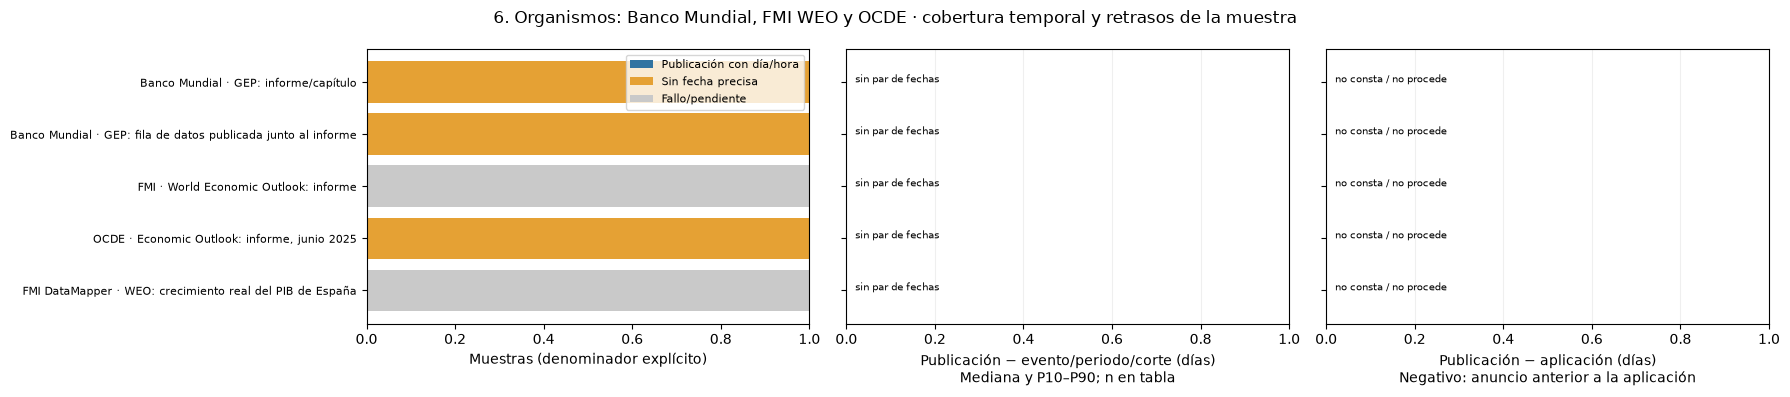

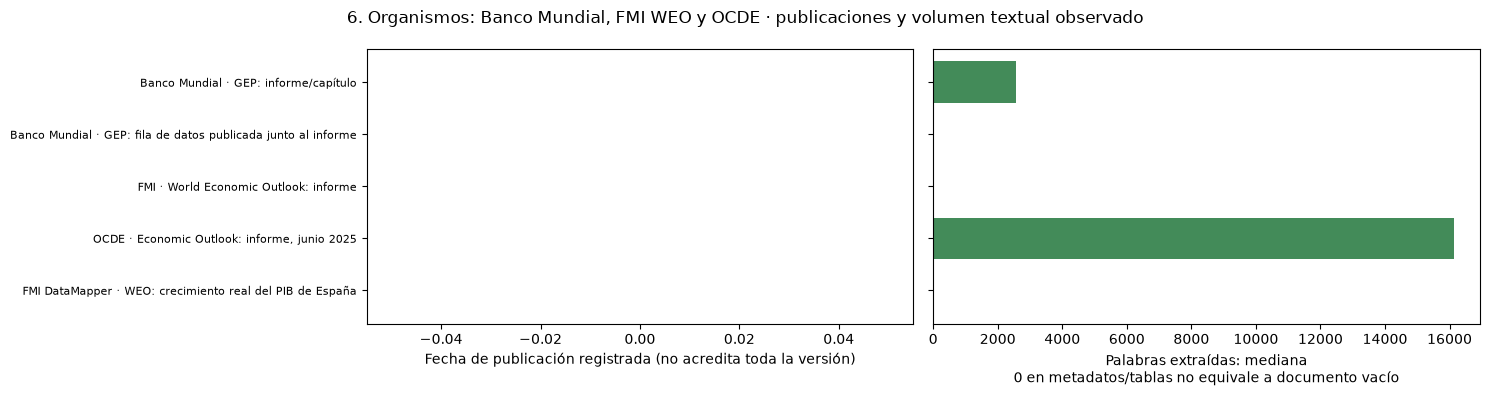

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
2,FMI,World Economic Outlook: informe,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/en/Publications/WEO
4,FMI DataMapper,WEO: crecimiento real del PIB de España,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/external/datamapper/api/v2/NGDP_RPCH/ESP


Ejemplo · Global Economic Prospects -- June 2026 -- Chapter 1 highlights 
URL: https://thedocs.worldbank.org/en/doc/2b672b3b0415d6b66c45b66579db4ef5-0050012026/related/GEP-Jun-2026-Chapter-1-Highlights.pdf 
Hash: 1ba208c26f116efc0a3014e2da4a5e67583c7e47839beda0e3733291e99937c5
 
 
Global Economic Prospects  Global Economic Prospects  Global Economic Prospects  
HIGHLIGHTS from Chapter 1: 
THE GLOBAL OUTLOOK 
Key Points 
• Global growth is expected to slow  to 2.5 percent in 2026, weaker than previous forecasts , 
before firming to 2.8 percent in 2027–28. 
• Amid surging energy prices, disruptions to commodity markets, and elevated uncertainty, 
growth in emerging market and developing economies (EMDEs) is projected to slow 
markedly, especially in commodity importers and those directly affected by the conflict. 
• Successive shocks since 2019, including the ongoing energy crisis, have weighed on per 
capita income growth. EMDEs excluding China and India are on course to experience 
nea

In [13]:
resumen_06 = mostrar_apartado(sonda, 6, '6. Organismos: Banco Mundial, FMI WEO y OCDE')

## 7. Datasets abiertos: Hugging Face, FOMC y Beige Book

<a id="datasets"></a>

**Elección:** útiles para prototipos y anotaciones; las fuentes oficiales de los apartados anteriores siguen siendo la referencia para texto y fechas.

| Dataset o tipo | Fuente recomendada | ¿Gratis? | Calidad, licencia y limitación |
|---|---|---|---|
| Comunicaciones de múltiples bancos | [aufklarer/central-bank-communications](https://huggingface.co/datasets/aufklarer/central-bank-communications) | Descarga pública gratuita; ficha declara CC BY 4.0 | Candidato compatible con la descripción de la captura; no se ha demostrado que sea exactamente su dataset. Incluye corpus/anotaciones; contrastar procedencia y fechas |
| Frases FOMC con tono anotado | [gtfintechlab/fomc_communication](https://huggingface.co/datasets/gtfintechlab/fomc_communication) | Sí; ficha declara CC BY-NC 4.0 | Adecuado para etiquetas hawkish/dovish/neutral; restringe uso comercial. No sustituye un archivo completo de documentos |
| Discursos de bancos centrales | [istat-ai/cb-speeches](https://huggingface.co/datasets/istat-ai/cb-speeches) | Acceso condicionado a cuenta y aceptación/solicitud según ficha | Revisar permisos del contenido original además de la licencia declarada. Para empezar, preferir descarga directa BIS |
| Beige Book | [Archivo oficial Fed](https://www.federalreserve.gov/monetarypolicy/beige-book-default.htm) | Sí, sin cuenta | Mejor procedencia para el texto completo; la captura no identifica un dataset concreto de Beige Book |

**Calidad y tiempo:** una etiqueta de sentimiento es una interpretación, no una afirmación oficial del banco. Registrar quién anotó, método y versión. Si un dataset contiene `meeting_date` pero no evidencia de publicación, esa fecha no basta para TimeGate. Usarlo como semilla y reconstruir la disponibilidad desde el original. No atribuir CC BY a todos los datasets de una plataforma.

Para la biblioteca general, aceptar textos cuya procedencia, licencia y extracción se hayan validado aunque su fecha exacta sea desconocida. Reconstruir la disponibilidad precisa solo cuando haga falta para el modo histórico; no dejar estos corpus fuera únicamente por ese dato ausente.

### Sonda: adquisición y mediciones

**Medición específica.** Cada dataset HF mantiene identificador, campos y etiquetas originales. Un `publication_date` del dataset es evidencia secundaria; no prueba la disponibilidad de cada frase ni la fecha de sus anotaciones. La falta de permisos se registra sin detener el Beige Book original. Para un backtest habría que reconstruir documentos padres, fechas, versiones y fecha de disponibilidad de las etiquetas.

In [14]:
inventario_07 = sonda.inventario(7)
display(inventario_07[["fuente", "tipo", "adaptador"]])
muestra_07 = sonda.ejecutar(7)

,fuente,tipo,adaptador
0,Hugging Face,aufklarer/central-bank-communications,huggingface
1,Hugging Face,gtfintechlab/fomc_communication,huggingface
2,Hugging Face,istat-ai/cb-speeches,huggingface
3,Fed,Beige Book original (sin dataset HF identificado),documento


6 intentos · 5 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,Hugging Face,aufklarer/central-bank-communications,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.04
1,Hugging Face,gtfintechlab/fomc_communication,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.00
2,Hugging Face,istat-ai/cb-speeches,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
3,Fed,Beige Book original (sin dataset HF identificado),3,3,2026-01-14 00:00:00+00:00,2026-04-15 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,1173.0,3,0,0.27


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,Hugging Face,aufklarer/central-bank-communications,OK,None,NaN,desconocida,None,NaN,NaN,"Campo del dataset, sin acreditar disponibilidad/versión original",sin_fecha,https://datasets-server.huggingface.co/rows
1,Hugging Face,gtfintechlab/fomc_communication,OK,None,NaN,desconocida,None,NaN,NaN,"Campo del dataset, sin acreditar disponibilidad/versión original",sin_fecha,https://datasets-server.huggingface.co/rows
2,Hugging Face,istat-ai/cb-speeches,ERROR_ACCESO,None,NaN,desconocida,None,NaN,NaN,,sin_muestra,istat-ai/cb-speeches
3,Fed,Beige Book original (sin dataset HF identificado),OK,None,2026-01-14,día,None,NaN,NaN,"etiqueta date: January 14, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202601-summary.htm
4,Fed,Beige Book original (sin dataset HF identificado),OK,None,2026-03-04,día,None,NaN,NaN,"etiqueta date: March 04, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202602-summary.htm
5,Fed,Beige Book original (sin dataset HF identificado),OK,None,2026-04-15,día,None,NaN,NaN,"etiqueta date: April 15, 2026",pendiente_versión,https://www.federalreserve.gov/monetarypolicy/beigebook202604-summary.htm


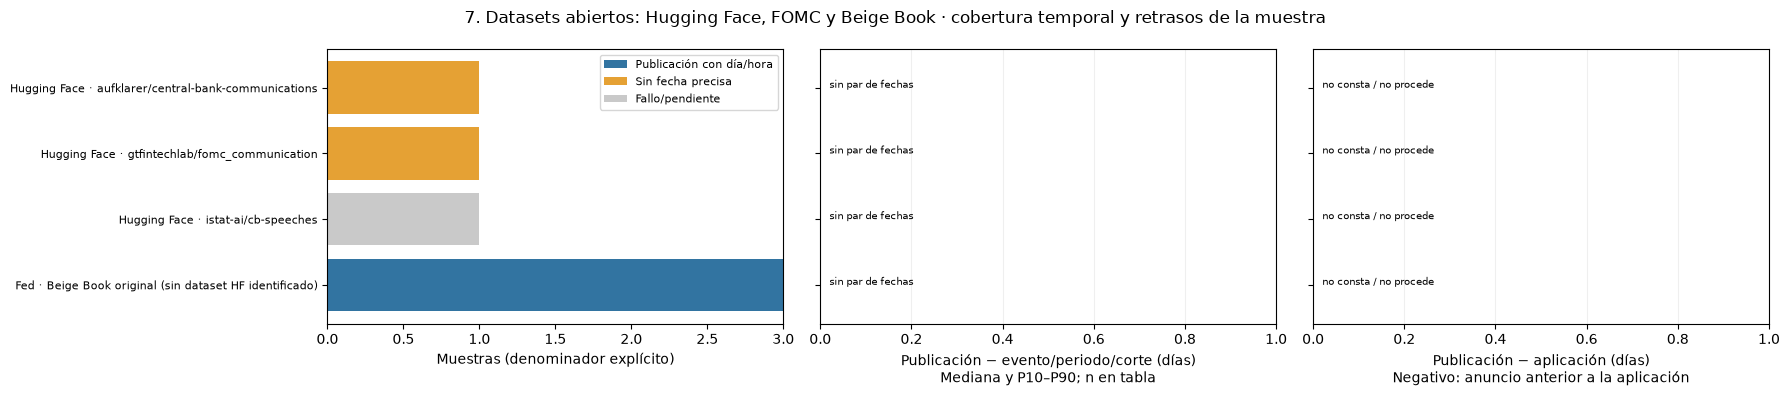

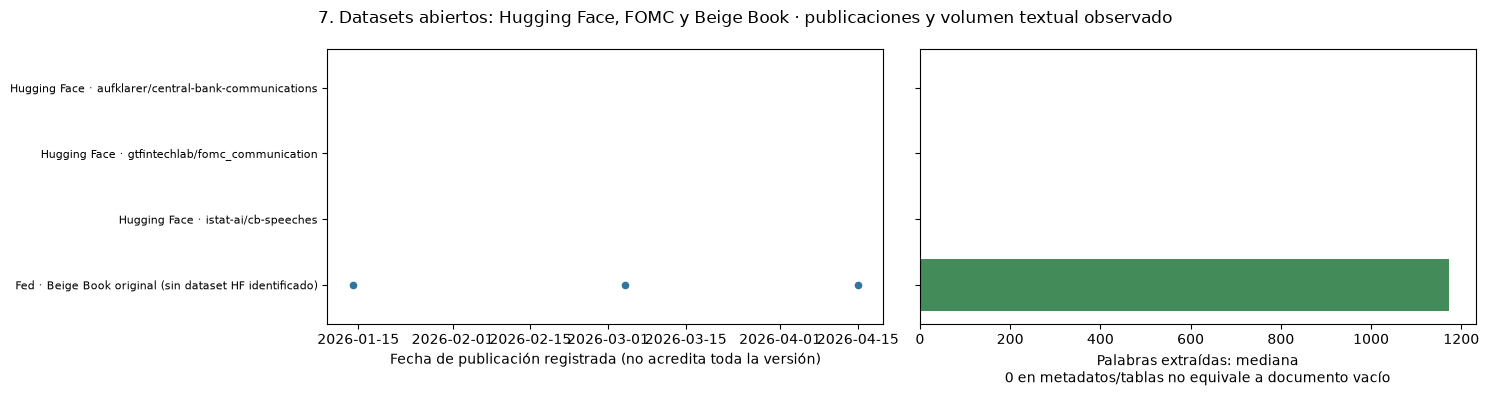

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
2,Hugging Face,istat-ai/cb-speeches,ERROR_ACCESO,HTTP 401; revisar acceso oficial,istat-ai/cb-speeches


Ejemplo · National Summary 
URL: https://www.federalreserve.gov/monetarypolicy/beigebook202601-summary.htm 
Hash: eacc0ff1f43668e67ca360572b467c4da0101b6e7f642ce50dbc8a7f82d78cd3
National Summary

Overall Economic Activity

Overall economic activity increased at a slight to modest pace in eight of the twelve Federal Reserve Districts, with three Districts reporting no change and one reporting a modest decline. This marks an improvement over the last three report cycles where a majority of Districts reported little change. Most banks reported slight to modest growth in consumer spending this cycle, largely attributed to the holiday shopping season. Several Districts also noted that spending was stronger among higher-income consumers with increased spending on luxury goods, travel, tourism, and experiential activities. Meanwhile, low to moderate income consumers were seen to be increasingly price sensitive and hesitant to spend on nonessential goods and services. Auto sales were little c

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,Fed,Beige Book original (sin dataset HF identificado),2026-03-04,0.584,eacc0ff1f43668e67ca360572b467c4da0101b6e7f642ce50dbc8a7f82d78cd3,3f4403ce0a6dc07b2c08cd2648d8912036b1ca704d1f6432465121976b475eee
1,Fed,Beige Book original (sin dataset HF identificado),2026-04-15,0.577,3f4403ce0a6dc07b2c08cd2648d8912036b1ca704d1f6432465121976b475eee,261af2eb6e45b1244c6b981f96105feacb224e5e29da15337902203ffebf0cf2


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [15]:
resumen_07 = mostrar_apartado(sonda, 7, '7. Datasets abiertos: Hugging Face, FOMC y Beige Book')

## 8. Estabilidad financiera

<a id="estabilidad"></a>

**Elección:** informe completo de la institución que lo produce, junto con tablas y anexos publicados. Son fuentes primarias para saber qué riesgos comunicaba cada organismo.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Fed Financial Stability Report | [FSR Fed](https://www.federalreserve.gov/publications/financial-stability-report.htm) | Sí | PDF/HTML y ediciones anteriores |
| BCE Financial Stability Review | [FSR BCE](https://www.ecb.europa.eu/pub/financial-stability/fsr/html/index.en.html) | Sí | Informe, capítulos y artículos |
| BoE Financial Stability Report | [Archivo FSR BoE](https://www.bankofengland.co.uk/sitemap/financial-stability-report) | Sí | HTML/PDF por edición |
| ESRB: informes de riesgo sistémico | [Reports ESRB](https://www.esrb.europa.eu/pub/reports/html/index.en.html) | Sí | Informes temáticos, anuales y anexos |
| OFR: evaluación y análisis | [Annual Reports OFR](https://www.financialresearch.gov/annual-reports/) | Sí | Informes anuales y material asociado |
| FSB: supervisión y vulnerabilidades | [Publications FSB](https://www.fsb.org/publications/) | Sí | Informes por tema y fecha |

**Calidad:** conservar gráficos y referencias a tablas junto al texto. “Estabilidad financiera” agrupa series distintas: no tratar un informe anual OFR y un FSR semestral como observaciones idénticas. Deduplicar informe completo y capítulos, sin perder su relación. Los recuentos de la captura no representan necesariamente todo el archivo actual.

### Sonda: adquisición y mediciones

**Medición específica.** Fed, BCE, BoE, ESRB, OFR y FSB conservan series separadas. Fecha de edición, fin del periodo analizado, corte de datos y publicación no se intercambian. Se miden páginas, palabras y tamaño; un informe que exceda el límite de páginas se señala como extracción parcial. Los gráficos no atribuyen igual frecuencia a todas las instituciones.

In [16]:
inventario_08 = sonda.inventario(8)
display(inventario_08[["fuente", "tipo", "adaptador"]])
muestra_08 = sonda.ejecutar(8)

,fuente,tipo,adaptador
0,Fed,Financial Stability Report,documento
1,BCE,Financial Stability Review,documento
2,BoE,Financial Stability Report,documento
3,ESRB,Informe de riesgo sistémico,documento
4,OFR,Annual Report,documento
5,FSB,Informe de supervisión y vulnerabilidades,documento


18 intentos · 18 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,Fed,Financial Stability Report,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,11802.0,0,0,15.22
1,BCE,Financial Stability Review,3,3,2025-05-21 00:00:00+00:00,2026-05-27 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,31194.0,3,0,1.19
2,BoE,Financial Stability Report,3,3,1996-10-31 00:00:00+00:00,1997-10-16 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,52.0,3,0,0.22
3,ESRB,Informe de riesgo sistémico,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,7908.0,2,0,2.08
4,OFR,Annual Report,3,3,2023-12-06 00:00:00+00:00,2025-11-19 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,572.0,3,0,0.11
5,FSB,Informe de supervisión y vulnerabilidades,3,3,2026-10-09 06:00:01+00:00,2026-10-14 04:00:00+00:00,0,0,NaN,NaN,NaN,NaN,279.0,3,0,1.26


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,Fed,Financial Stability Report,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.federalreserve.gov/publications/files/financial-stability-report-20260508.pdf
1,Fed,Financial Stability Report,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.federalreserve.gov/publications/files/financial-stability-report-20251107.pdf
2,Fed,Financial Stability Report,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.federalreserve.gov/publications/files/financial-stability-report-20250425.pdf
3,BCE,Financial Stability Review,OK,None,2026-05-27,día,None,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/financial-stability-publications/fsr/html/ecb.fsr202605~50566915...
4,BCE,Financial Stability Review,OK,None,2025-11-26,día,None,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/financial-stability-publications/fsr/html/ecb.fsr202511~263b5810...
5,BCE,Financial Stability Review,OK,None,2025-05-21,día,None,NaN,NaN,meta citation_online_date,pendiente_versión,https://www.ecb.europa.eu/press/financial-stability-publications/fsr/html/ecb.fsr202505~0cde5244...
6,BoE,Financial Stability Report,OK,None,1996-10-31,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/financial-stability-report/1996/autumn-1996
7,BoE,Financial Stability Report,OK,None,1997-10-16,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/financial-stability-report/1997/autumn-1997
8,BoE,Financial Stability Report,OK,None,1997-03-03,día,None,NaN,NaN,fecha visible .published-date,pendiente_versión,https://www.bankofengland.co.uk/financial-stability-report/1997/spring-1997
9,ESRB,Informe de riesgo sistémico,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.esrb.europa.eu/pub/pdf/reports/esrb.report202607_AImodelscybercapabilites.en.pdf?a6d...


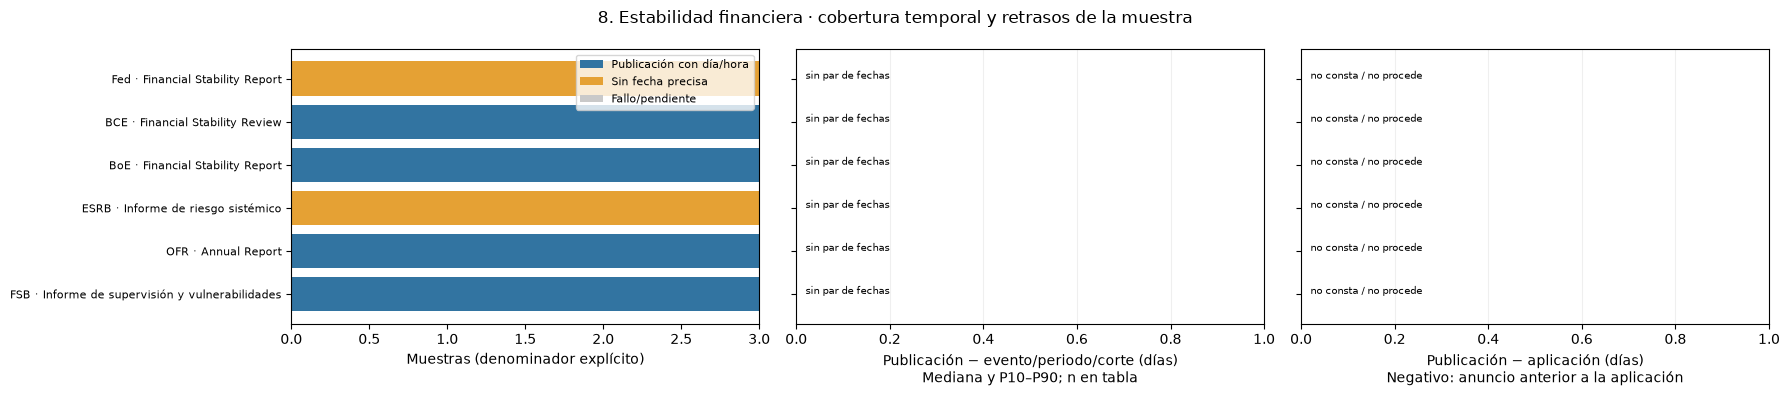

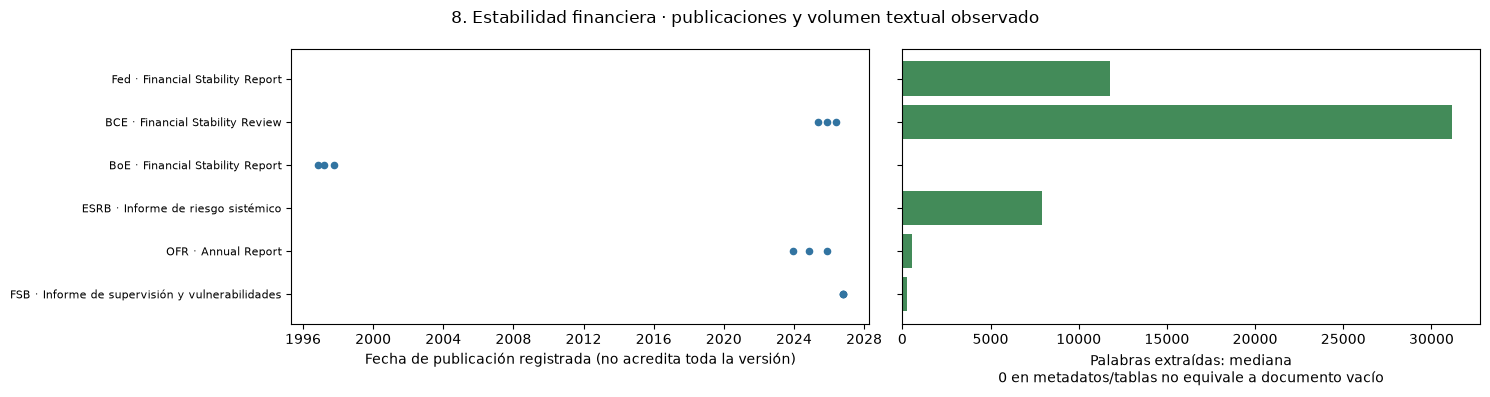

Ejemplo · Financial Stability Report, May 2026 
URL: https://www.federalreserve.gov/publications/files/financial-stability-report-20260508.pdf 
Hash: 1aabf0182706b17f9ff46b14853fa06d863fe1327e1402aa66e73294572a53da
Financial Stability Report
May 2026
BOARD OF GO VERNORS OF THE FEDERAL RESER VE SYST EM

The Federal Reserve System is the central
bank of the United States. It performs five key
functions to promote the effective operation
of the U.S. economy and, more generally, the
public interest.
The Federal Reserve
■ conducts the nation’s monetary policy to promote maximum employment
and stable prices in the U.S. economy;
■ promotes the stability of the financial system and seeks to minimize
and contain systemic risks through active monitoring and engagement in
the U.S. and abroad;
■ promotes the safety and soundness of individual financial institutions
and monitors their impact on the financial system as a whole;
■ fosters payment and settlement system safety and efficiency through
se

,fuente,tipo,fecha_publicacion,cambio_vocabulario_jaccard,version_anterior,version_actual
0,BCE,Financial Stability Review,2025-11-26,0.480,51e277da2e1d4fa93a0b5834b0947f658df8793cc43e4ebaa3668f5d881ad1f6,07b8f2767774a66e88107e89bea869900442848a5b9b4aae961c24c7c4c95af4
1,BCE,Financial Stability Review,2026-05-27,0.483,07b8f2767774a66e88107e89bea869900442848a5b9b4aae961c24c7c4c95af4,6f00b4abd4eb4f2282b8c5d44ddc1c428cbb4a3d058d9bc04b0c75d26db253af
2,BoE,Financial Stability Report,1997-03-03,0.211,124d49189c1e562ac10a7f47130cedbaafcc43698f92485ee0481a5f9ed6fa2f,afca2392d62e8cd99cfdae67e79d07dba90f778fffe77879ce8a5e82ffafe12f
3,BoE,Financial Stability Report,1997-10-16,0.111,afca2392d62e8cd99cfdae67e79d07dba90f778fffe77879ce8a5e82ffafe12f,0ae7c369d3e49cc9e7c475c18623dd435b93d8ce57c0f57bd8aa95e1c9085b82
4,OFR,Annual Report,2024-11-20,0.766,7f4e15493743034acafe5d5593cc1a3a907bf276a61ca6f3979e5182a678df4c,a925978eba432a18dd9edf70de6ea352a09f1ee2f80efaab0605a937db1298ca
5,OFR,Annual Report,2025-11-19,0.714,a925978eba432a18dd9edf70de6ea352a09f1ee2f80efaab0605a937db1298ca,dd9edc8cfe38ddc885d11622b357ba2d1cc3361b39b1c5a6b20e08258038a5ef
6,FSB,Informe de supervisión y vulnerabilidades,2026-10-14T04:00:00+00:00,0.882,c62981b4fbc7951da74e44b754d60ee259210ca54e9925068a27a1b779cd42a9,2354ff801f69d86cb64a226c6ff4800ca68618c6536929125fccf71e9ace4660
7,FSB,Informe de supervisión y vulnerabilidades,2026-10-14T04:00:00+00:00,0.893,2354ff801f69d86cb64a226c6ff4800ca68618c6536929125fccf71e9ace4660,b82f993708d2c073177d4bccc4812e7b62c437b853bdf8503439fc1f919e4be2


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [17]:
resumen_08 = mostrar_apartado(sonda, 8, '8. Estabilidad financiera')

## 9. BIS Quarterly Review y Working Papers

<a id="bis-papers"></a>

**Elección:** catálogo oficial BIS, tanto para el documento como para número de serie, autores y fecha.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| Quarterly Review completo y artículos | [BIS Quarterly Review](https://www.bis.org/publications/qr) | Sí | Ediciones y artículos HTML/PDF |
| Working Papers | [BIS Working Papers](https://www.bis.org/publications/working-paper) | Sí | Catálogo y PDFs individuales |

**Calidad y tiempo:** separar el informe trimestral de sus artículos y vincularlos con un documento padre. Un Working Paper no equivale automáticamente a un artículo revisado por una revista. Guardar la versión y el número de la serie. Para TimeGate, contrastar la fecha de lanzamiento con la portada y la ficha: la fecha de modificación de una página migrada puede ser posterior a la publicación original.

### Sonda: adquisición y mediciones

**Medición específica.** Quarterly Review, artículo y Working Paper son familias distintas. La ficha consultada puede contener solo resumen/metadatos; no se presume el informe completo. Se registran publicación y número/URL cuando existen. La portada de un WP con mes y año no se transforma en el primer día del mes.

In [18]:
inventario_09 = sonda.inventario(9)
display(inventario_09[["fuente", "tipo", "adaptador"]])
muestra_09 = sonda.ejecutar(9)

,fuente,tipo,adaptador
0,BIS,Quarterly Review: edición completa,documento
1,BIS,"Working Paper: autores, serie y resumen",documento
2,BIS,Quarterly Review: artículo,documento


7 intentos · 6 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BIS,Quarterly Review: edición completa,3,3,2026-03-16 00:00:00+00:00,2026-09-14 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,186.0,0,0,0.45
1,BIS,"Working Paper: autores, serie y resumen",3,3,2026-10-06 00:00:00+00:00,2026-10-13 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,452.0,0,0,0.39
2,BIS,Quarterly Review: artículo,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BIS,Quarterly Review: edición completa,OK,None,2026-09-14,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/qr-202609
1,BIS,Quarterly Review: edición completa,OK,None,2026-06-15,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/qr-202606
2,BIS,Quarterly Review: edición completa,OK,None,2026-03-16,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/qr-202603
3,BIS,"Working Paper: autores, serie y resumen",OK,None,2026-10-13,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/working-paper-1382-are-stablecoins-and-bank-deposits-substitutes
4,BIS,"Working Paper: autores, serie y resumen",OK,None,2026-10-12,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/working-paper-1381-transformative-ai-and-demand-bottlenecks
5,BIS,"Working Paper: autores, serie y resumen",OK,None,2026-10-06,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publications/working-paper-1380-chasing-el-dorado-gold-under-shifting-geopol...
6,BIS,Quarterly Review: artículo,ERROR_ACCESO,None,NaN,desconocida,None,NaN,NaN,,sin_muestra,https://www.bis.org/publ/qtrpdf/r2503a.htm


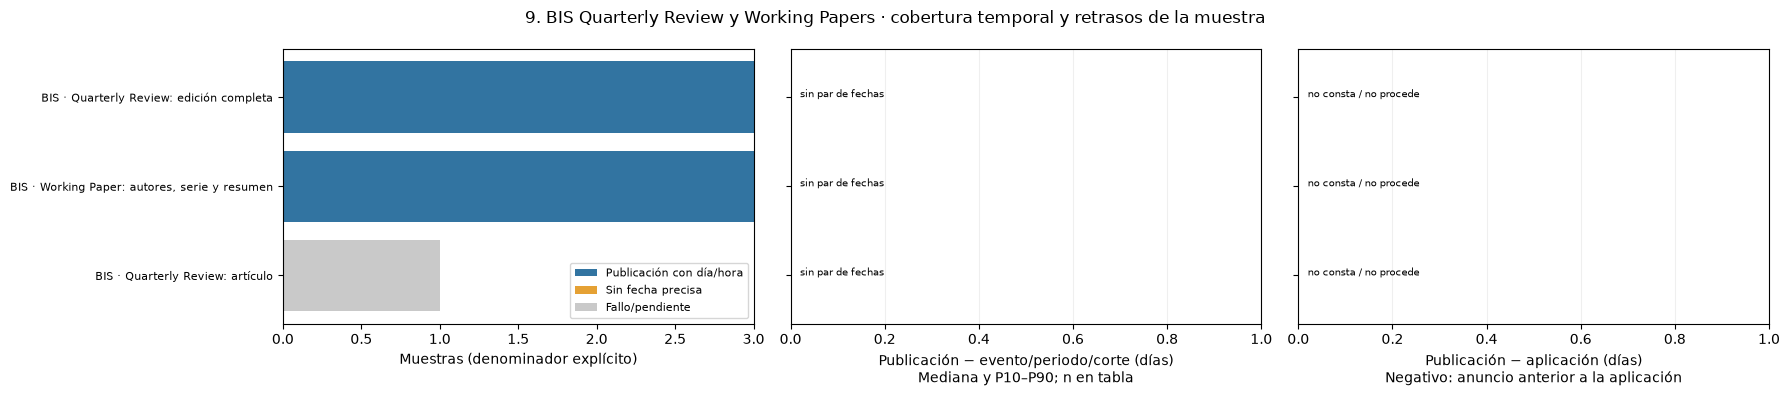

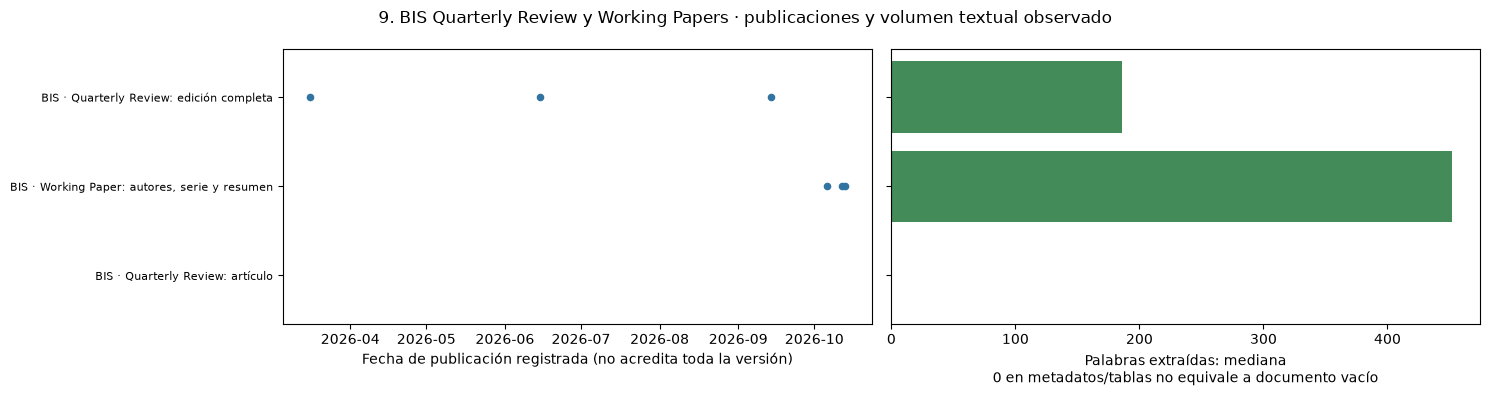

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
6,BIS,Quarterly Review: artículo,ERROR_ACCESO,HTTP 404; revisar acceso oficial,https://www.bis.org/publ/qtrpdf/r2503a.htm


Ejemplo · BIS Quarterly Review, September 2026 
URL: https://www.bis.org/publications/qr-202609 
Hash: ec563c1db921e8495342ffce90c4cbdb24e200cdd57962bb0619c92cf1d96a1b
BIS Quarterly Review, September 2026

Yields climb, yet risk appetite holds firm

In the review period flare-ups in geopolitical tensions tested the positive momentum that had characterised the first half of the year. Markets faced bouts of volatility as hostilities in the Strait of Hormuz heightened uncertainty about the inflation and monetary policy outlook. On top of that, lingering concerns about the sustainability of fiscal burdens added to the pressure. The prospects of higher rates stemming from these macroeconomic challenges compounded markets’ unease about valuations and possible overinvestment in the tech sector, disrupting the equity momentum driven by artificial intelligence (AI). Yet while investors’ risk appetite ebbed and flowed, it proved resilient on the whole.

Articles

Media

Frank Smets and Gaston Ge

In [19]:
resumen_09 = mostrar_apartado(sonda, 9, '9. BIS Quarterly Review y Working Papers')

## 10. FMI Global Financial Stability Report — GFSR

<a id="gfsr"></a>

**Elección:** FMI como editor original. Es una fuente central para riesgos financieros globales y debe formar parte del corpus aunque alguna ruta de acceso automático falle.

| Información solicitada | Fuente recomendada | ¿Gratis? | Acceso previsto |
|---|---|---|---|
| GFSR completo | [Serie oficial GFSR](https://www.imf.org/en/Publications/GFSR) | Sí, PDF digital | Ediciones, capítulos y anexos |
| Ejemplo de PDF completo | [GFSR abril de 2026, texto inglés](https://www.imf.org/-/media/files/publications/gfsr/2026/april/english/text.pdf) | Sí, enlace público | PDF original descargable |
| Ruta editorial alternativa | [IMF eLibrary: estabilidad financiera](https://www.elibrary.imf.org/subject/082) | Acceso gratuito a materiales abiertos; comprobar el documento concreto | Ficha editorial y versiones disponibles |

**Calidad y acceso:** la captura marca “BLOQUEADA” por WAF; eso describe un obstáculo de adquisición, no un precio. Si falla la descarga automática, usar el enlace oficial al PDF o descarga manual con registro de procedencia. No es necesario empezar comprando el informe impreso. Una traducción de un resumen ejecutivo no sustituye el informe completo en inglés.

**Tiempo:** ciertos registros de ediciones antiguas pueden reflejar la incorporación al portal. Comprobar fecha original de edición/lanzamiento y conservar evidencia; no usar sin más la fecha reciente de la ficha migrada.

### Sonda: adquisición y mediciones

**Medición específica.** Se conserva por separado la ficha descubierta, el PDF fijo de abril de 2026 y la ruta editorial alternativa. **El PDF fijo no hereda la fecha de la última ficha descubierta:** pueden ser ediciones distintas. La falta de fecha verificada queda visible; un bloqueo de acceso es un resultado de la sonda, no prueba de que el informe sea de pago.

In [20]:
inventario_10 = sonda.inventario(10)
display(inventario_10[["fuente", "tipo", "adaptador"]])
muestra_10 = sonda.ejecutar(10)

,fuente,tipo,adaptador
0,FMI,GFSR: ficha de una edición,documento
1,FMI,GFSR: texto del informe completo (extracción limitada por configuración),documento
2,FMI eLibrary,Ficha editorial alternativa GFSR,documento


3 intentos · 0 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,FMI,GFSR: ficha de una edición,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.0
1,FMI,GFSR: texto del informe completo (extracción limitada por configuración),1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.0
2,FMI eLibrary,Ficha editorial alternativa GFSR,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.0


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,FMI,GFSR: ficha de una edición,ERROR_ACCESO,None,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/en/Publications/GFSR
1,FMI,GFSR: texto del informe completo (extracción limitada por configuración),ERROR_ACCESO,None,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/-/media/files/publications/gfsr/2026/april/english/text.pdf
2,FMI eLibrary,Ficha editorial alternativa GFSR,ERROR_ACCESO,None,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.elibrary.imf.org/subject/082


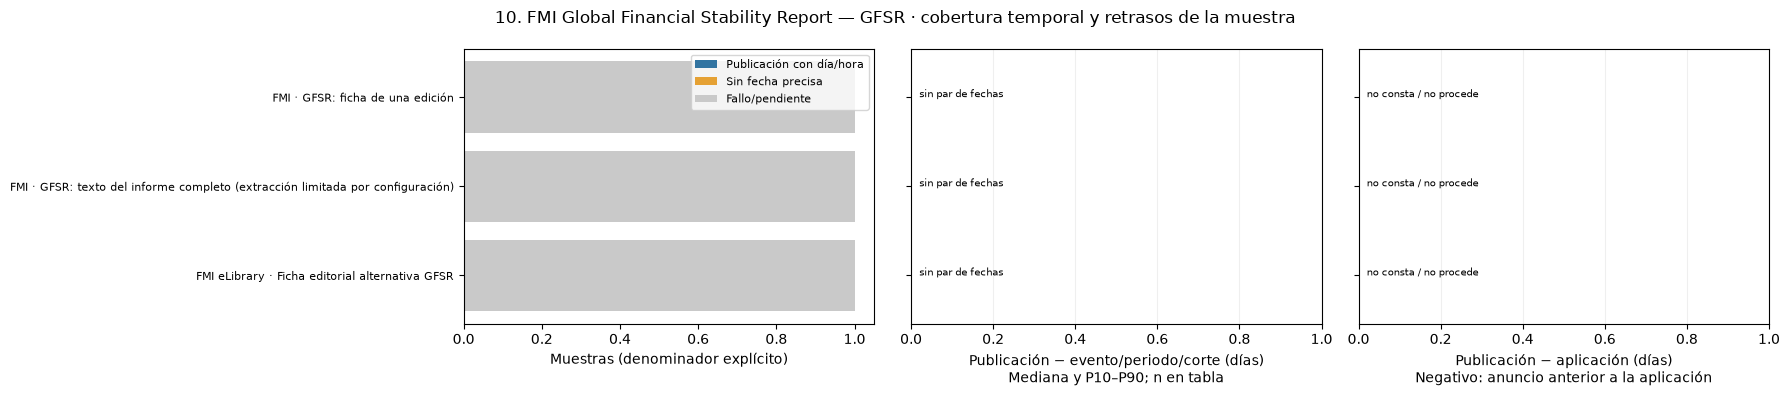

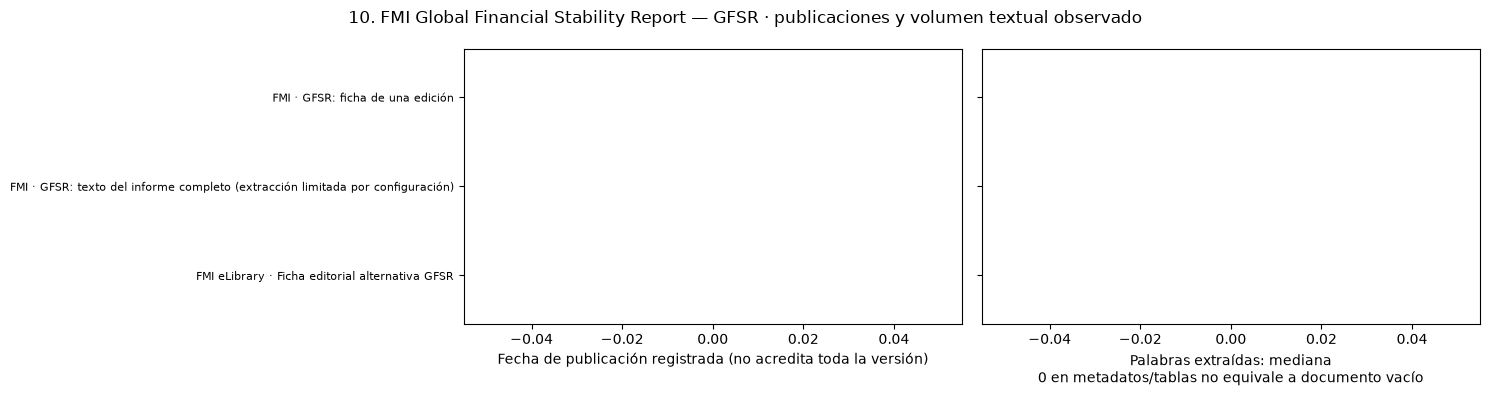

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
0,FMI,GFSR: ficha de una edición,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/en/Publications/GFSR
1,FMI,GFSR: texto del informe completo (extracción limitada por configuración),ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/-/media/files/publications/gfsr/2026/april/english/text.pdf
2,FMI eLibrary,Ficha editorial alternativa GFSR,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.elibrary.imf.org/subject/082


TimeGate al 2026-10-14T00:00:00+00:00: 0 textos completos con versión acreditada. El resto conserva su fecha conocida para la biblioteca general.


In [21]:
resumen_10 = mostrar_apartado(sonda, 10, '10. FMI Global Financial Stability Report — GFSR')

## 11. Papers de crisis

<a id="papers-crisis"></a>

**Elección:** buscar primero el documento publicado por su institución o una versión autorizada del autor. La calidad científica depende de cada trabajo; el proveedor de descarga, por sí solo, no demuestra revisión o robustez.

| Tipo de fuente | Recomendación y enlace | ¿Gratis? | Uso y límites |
|---|---|---|---|
| Working papers institucionales | [BIS](https://www.bis.org/publications/working-paper) y [BCE](https://www.ecb.europa.eu/press/research-publications/working-papers/html/index.en.html) | Sí, publicaciones propuestas | Original, autores y serie; buenas primeras fuentes sobre crisis financieras |
| Preprints | [arXiv](https://arxiv.org/) y [documentación de su API](https://info.arxiv.org/help/api/index.html) | Lectura pública gratuita | API de metadatos; PDF y versiones individuales. Cobertura económica selectiva; no confundir preprint y versión revisada |
| Working papers y manuscritos | [SSRN](https://www.ssrn.com/); [explicación del acceso del proveedor](https://blog.ssrn.com/2020/08/03/what-is-the-ssrn-login-worth-core-values-and-commitments-to-researchers/) | Muchos gratuitos; puede requerir cuenta gratuita | Comprobar archivo concreto y condiciones; no asumir API masiva pública |
| NBER Working Papers | [Condiciones de acceso NBER](https://www.nber.org/subscribe) | Parcial: cupos, acceso elegible o suscripción | Priorizar copia autorizada del autor/institución si el PDF exige pago; no es una fuente totalmente gratuita |
| Descubrimiento por DOI | [Crossref REST API](https://www.crossref.org/documentation/retrieve-metadata/rest-api/) | Metadatos públicos gratuitos | Título, autores, DOI y fechas; no entrega necesariamente texto completo |
| Localizar copias de acceso abierto | [Unpaywall API v2](https://unpaywall.org/api/v2) | API gratuita con identificación por email y límites | Consultar por DOI; enlaza ubicaciones abiertas, sin garantizar una copia para todo paper |

**Orden recomendado:** original institucional → versión editorial abierta → manuscrito autorizado del autor → preprint documentado. Si solo queda una versión de pago, guardar referencia y estado pendiente; decidir más adelante si merece comprarla.

**Alcance:** la imagen no aporta la bibliografía de sus 386 papers/37 crisis. No se puede afirmar que se haya localizado ese conjunto exacto. Antes de recolectarlo, definir crisis, criterios de inclusión y lista de referencias. Deduplicar por DOI y conservar separadas las versiones que cambian resultados.

### Sonda: adquisición y mediciones

**Medición específica.** Texto institucional, preprint, ficha SSRN/NBER, metadatos Crossref y copia localizada por Unpaywall tienen registros independientes. Crossref conserva online/print por separado; no acredita acceso al PDF. arXiv fija el documento a v1. Unpaywall localiza acceso abierto actual, pero no demuestra cuándo se abrió esa copia. La bibliografía completa de la captura sigue pendiente.

In [22]:
inventario_11 = sonda.inventario(11)
display(inventario_11[["fuente", "tipo", "adaptador"]])
muestra_11 = sonda.ejecutar(11)

,fuente,tipo,adaptador
0,BIS,Working Paper sobre crisis,documento
1,BCE,Working Paper institucional,documento
2,arXiv,Preprint sobre crisis financiera,arxiv
3,SSRN,Manuscrito: ficha y resumen,documento
4,NBER,"Working Paper: ficha, autores y resumen",documento
5,Crossref,Metadatos bibliográficos,crossref
6,Unpaywall,Ubicación de copia abierta,unpaywall


9 intentos · 7 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BIS,Working Paper sobre crisis,1,1,2012-12-10 00:00:00+00:00,2012-12-10 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,131.0,0,0,0.13
1,BCE,Working Paper institucional,3,3,NaT,NaT,3,0,NaN,NaN,NaN,NaN,15817.0,1,0,4.16
2,arXiv,Preprint sobre crisis financiera,1,1,2009-05-02 17:34:38+00:00,2009-05-02 17:34:38+00:00,0,0,NaN,NaN,NaN,NaN,15170.0,0,0,2.14
3,SSRN,Manuscrito: ficha y resumen,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
4,NBER,"Working Paper: ficha, autores y resumen",1,1,2008-03-14 00:00:00+00:00,2008-03-14 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,448.0,0,0,0.09
5,Crossref,Metadatos bibliográficos,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.00
6,Unpaywall,Ubicación de copia abierta,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BIS,Working Paper sobre crisis,OK,None,2012-12-10,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publ/work395.htm
1,BCE,Working Paper institucional,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.ecb.europa.eu/pub/pdf/scpwps/ecb.wp3299~01776adb36.en.pdf?2546b35f40f6a9c66450f0ab17...
2,BCE,Working Paper institucional,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.ecb.europa.eu/pub/pdf/scpwps/ecb.wp3299~01776adb36.en.pdf
3,BCE,Working Paper institucional,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.ecb.europa.eu/pub/pdf/scpwps/ecb.wp3298~06485c09a7.en.pdf?6c86b55d23cc785deb9bf6946b...
4,arXiv,Preprint sobre crisis financiera,OK,None,2009-05-02T17:34:38+00:00,hora,None,NaN,NaN,Atom published y PDF fijado a 0905.0220v1,pendiente_versión,https://arxiv.org/pdf/0905.0220v1
5,SSRN,Manuscrito: ficha y resumen,ERROR_ACCESO,None,NaN,desconocida,None,NaN,NaN,,sin_muestra,https://papers.ssrn.com/sol3/papers.cfm?abstract_id=1106608
6,NBER,"Working Paper: ficha, autores y resumen",OK,None,2008-03-14,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.nber.org/papers/w13882
7,Crossref,Metadatos bibliográficos,OK,None,2008-03,mes,None,NaN,NaN,"Crossref published-online: fecha editorial, no apertura del PDF",pendiente_versión,https://api.crossref.org/works/10.3386/w13882
8,Unpaywall,Ubicación de copia abierta,PENDIENTE,None,NaN,desconocida,None,NaN,NaN,,sin_muestra,10.3386/w13882


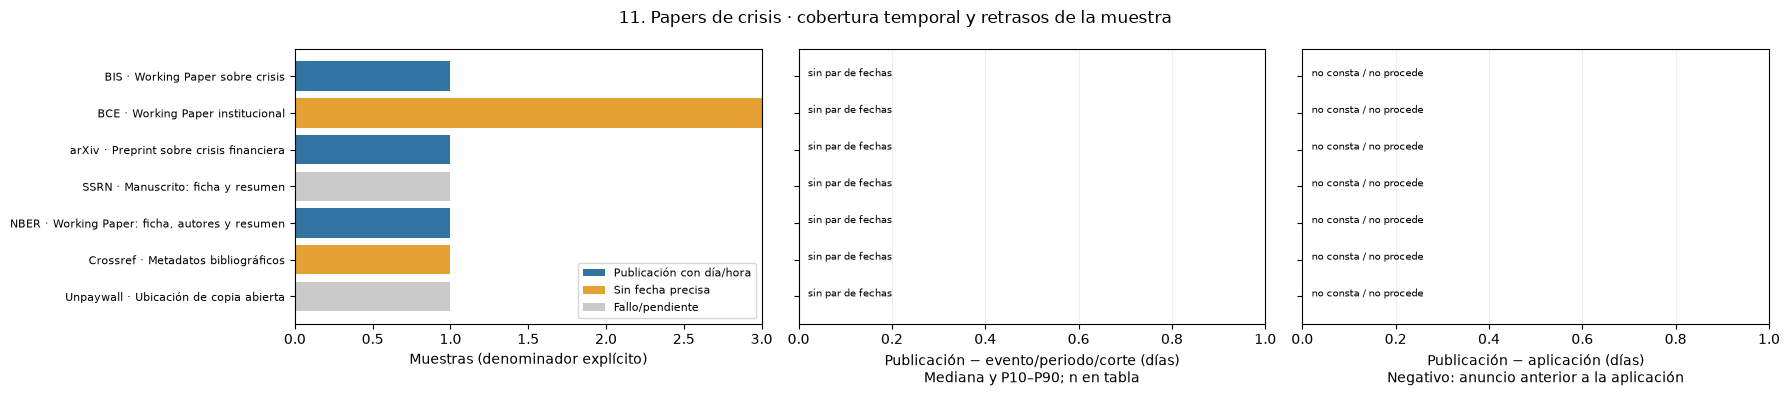

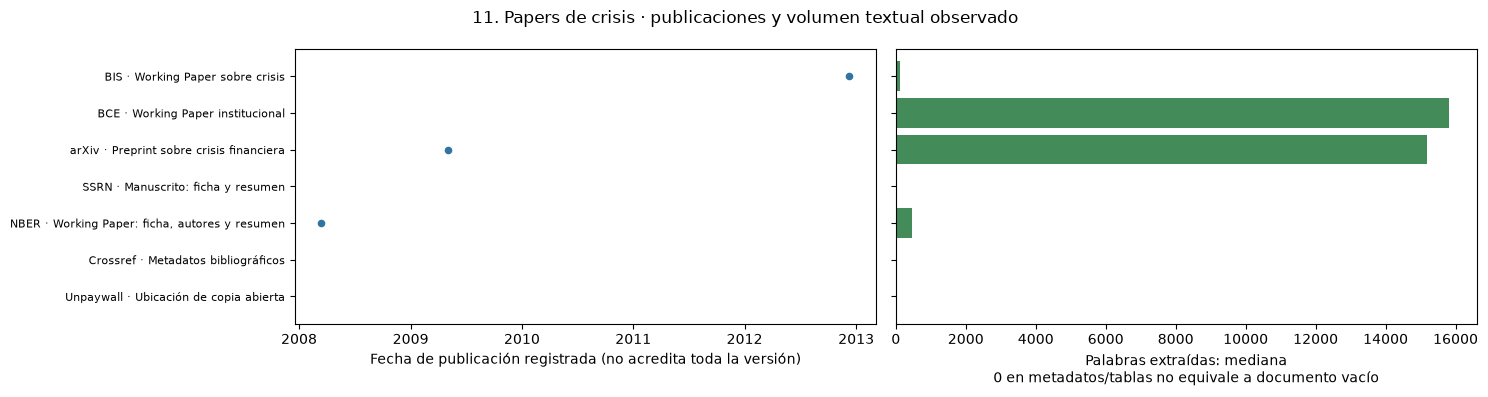

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
5,SSRN,Manuscrito: ficha y resumen,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://papers.ssrn.com/sol3/papers.cfm?abstract_id=1106608
8,Unpaywall,Ubicación de copia abierta,PENDIENTE,UNPAYWALL_EMAIL pendiente; completar variable de entorno con email real,10.3386/w13882


Ejemplo · The financial cycle and macroeconomics: what have we learnt? 
URL: https://www.bis.org/publ/work395.htm 
Hash: 939d77eab62e15116cbca56b304f2dd281e811142bc22faa2c8296a62d10f7ce
The financial cycle and macroeconomics: what have we learnt?

It is high time we rediscovered the role of the financial cycle in macroeconomics. In the environment that has prevailed for at least three decades now, it is not possible to understand business fluctuations and the corresponding analytical and policy challenges without understanding the financial cycle. This calls for a rethink of modelling strategies and for significant adjustments to macroeconomic policies. This essay highlights the stylised empirical features of the financial cycle, conjectures as to what it may take to model it satisfactorily, and considers its policy implications. In the discussion of policy, the essay pays special attention to the bust phase, which is less well explored and raises much more controversial issues.

Autho

In [23]:
resumen_11 = mostrar_apartado(sonda, 11, '11. Papers de crisis')

## 12. Huellas de crisis

<a id="huellas"></a>

**Elección:** bases documentadas de crisis como referencia, y construcción propia de las “huellas”. Las 18 crisis y 7 familias de la captura son una selección/taxonomía del proyecto; no identifican por sí mismas una descarga existente.

| Información necesaria | Fuente recomendada | ¿Gratis? | Calidad y limitación |
|---|---|---|---|
| Episodios de crisis europeas | [Financial crises database ESRB](https://www.esrb.europa.eu/pub/financial-crises/html/index.en.html) | Sí, descarga pública | Definiciones, episodios y documentación institucional |
| Crisis bancarias internacionales | [FMI: Systemic Banking Crises Database 1970–2025](https://www.elibrary.imf.org/abstract/journals/001/2026/094/article-A001-en.xml) | Trabajo digital abierto | Actualización documentada; localizar anexos y distinguir episodio/país |
| Referencia histórica del FMI | [Laeven y Valencia, 2018](https://www.elibrary.imf.org/abstract/journals/001/2018/206/article-A001-en.xml) | Texto digital abierto | Versión anterior útil para reproducibilidad; no mezclar vintages |
| Series macrofinancieras de largo plazo | [Jordà–Schularick–Taylor Macrohistory Database](https://www.macrohistory.net/database/) | Sí; CC BY-NC-SA 4.0 según sus términos | Datos, cronología y documentación; uso no comercial y condiciones de atribución/compartición |
| Familias, señales y huellas | Elaboración propia a partir de las bases y documentos anteriores | Sin compra de un dataset propio; procesamiento aparte | Definir variables, reglas, evidencias y versión de la clasificación |

**Tiempo:** una crisis identificada retrospectivamente en una base publicada en 2026 no era una etiqueta disponible para operar en 2008. Separar el catálogo ex post para evaluación de los indicadores y documentos disponibles en cada fecha. Reconciliar diferencias de definición entre fuentes; no fusionar episodios solo por compartir año.

En consulta general, el análisis retrospectivo es conocimiento útil para los agentes y puede incorporarse con su metodología y procedencia. La restricción de disponibilidad anterior al evento se reserva a backtests o simulaciones históricas.

### Sonda: adquisición y mediciones

**Medición específica.** Las filas ESRB y Macrohistory son ejemplos de bases revisables; las metodologías FMI pertenecen a ediciones identificadas. La fecha de inicio de una crisis es una etiqueta retrospectiva, no una señal disponible ese día. Las huellas reproducibles exigirían el vintage, variables y reglas; esta sonda muestra los datos de ejemplo y no fabrica las 18 crisis ni las siete familias de la captura.

In [24]:
inventario_12 = sonda.inventario(12)
display(inventario_12[["fuente", "tipo", "adaptador"]])
muestra_12 = sonda.ejecutar(12)

,fuente,tipo,adaptador
0,ESRB,Un episodio de la base de crisis europeas,tabla
1,FMI,Systemic Banking Crises Database 1970–2025: documento y metodología,documento
2,FMI,Laeven–Valencia 2018: versión histórica documentada,documento
3,Macrohistory,Una observación macrofinanciera histórica,tabla


5 intentos · 3 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,ESRB,Un episodio de la base de crisis europeas,2,2,NaT,NaT,2,0,NaN,NaN,NaN,NaN,0.0,0,0,0.09
1,FMI,Systemic Banking Crises Database 1970–2025: documento y metodología,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
2,FMI,Laeven–Valencia 2018: versión histórica documentada,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
3,Macrohistory,Una observación macrofinanciera histórica,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,1.41


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,ESRB,Un episodio de la base de crisis europeas,OK,2007-12,None,desconocida,None,NaN,NaN,Vintage/fecha de publicación de las cifras no acreditado,sin_fecha,https://www.esrb.europa.eu/pub/fcdb/esrb.fcdb20220120.en.xlsx?fd2dd3a0418fccecb99d90e27ebc1ded
1,ESRB,Un episodio de la base de crisis europeas,OK,2007-12,None,desconocida,None,NaN,NaN,Vintage/fecha de publicación de las cifras no acreditado,sin_fecha,https://www.esrb.europa.eu/pub/fcdb/esrb.fcdb20220120.en.xlsx
2,FMI,Systemic Banking Crises Database 1970–2025: documento y metodología,ERROR_ACCESO,NaN,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/en/publications/wp/issues/2026/05/14/systemic-banking-crises-database-1970-2...
3,FMI,Laeven–Valencia 2018: versión histórica documentada,ERROR_ACCESO,NaN,None,desconocida,None,NaN,NaN,,sin_muestra,https://www.imf.org/en/Publications/WP/Issues/2018/09/14/Systemic-Banking-Crises-Revisited-46232
4,Macrohistory,Una observación macrofinanciera histórica,OK,NaN,None,desconocida,None,NaN,NaN,Vintage/fecha de publicación de las cifras no acreditado,sin_fecha,https://www.macrohistory.net/app/download/9834512569/JSTdatasetR6.xlsx?t=1763503850


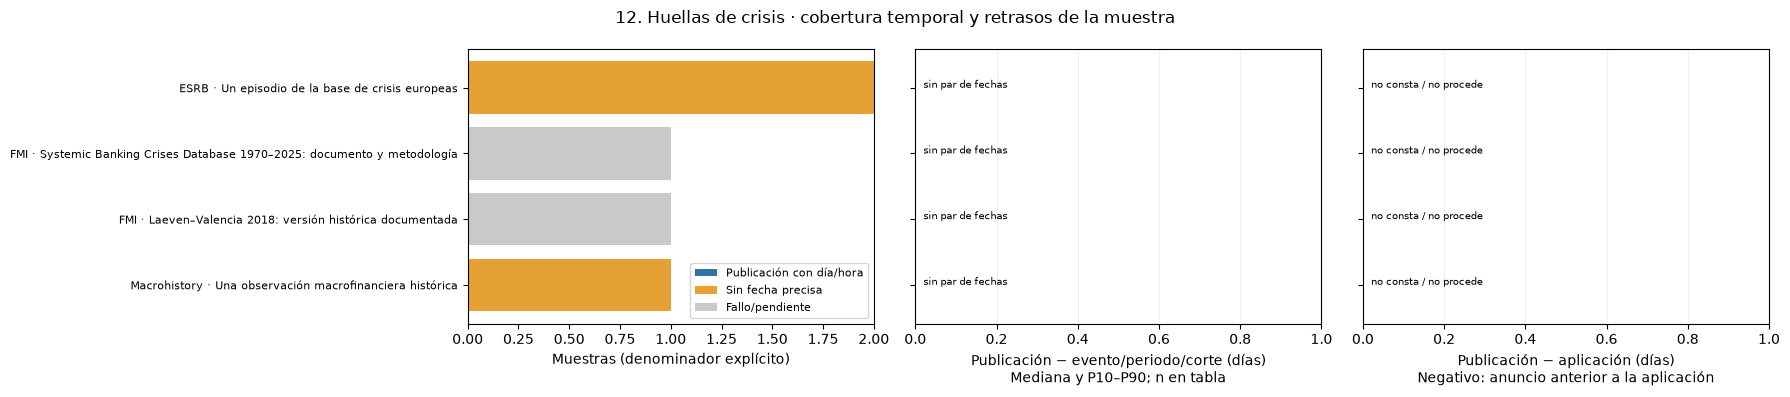

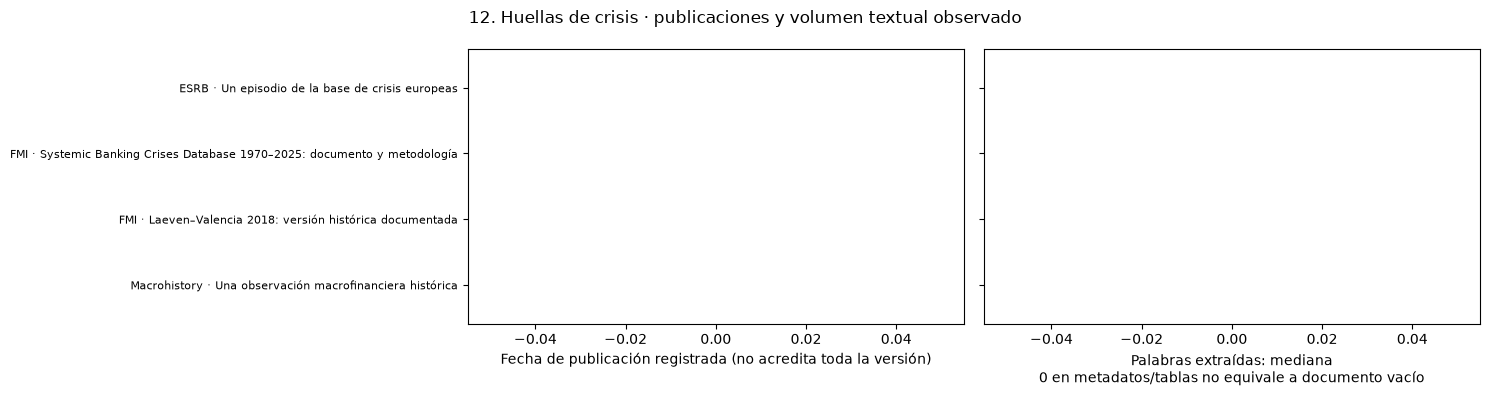

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
2,FMI,Systemic Banking Crises Database 1970–2025: documento y metodología,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/en/publications/wp/issues/2026/05/14/systemic-banking-crises-database-1970-2...
3,FMI,Laeven–Valencia 2018: versión histórica documentada,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://www.imf.org/en/Publications/WP/Issues/2018/09/14/Systemic-Banking-Crises-Revisited-46232


Ejemplo · Un episodio de la base de crisis europeas 
URL: https://www.esrb.europa.eu/pub/fcdb/esrb.fcdb20220120.en.xlsx?fd2dd3a0418fccecb99d90e27ebc1ded 
Hash: bf3535247da708b5ed77a43a356640b8436b5c7e35038b6bbe5d69241abc5a87
[{'Country': 'AT', 'Event': 1.0, 'Start date': '2007-12', 'End of crisis management date': '2014-12', 'System back to "normal" date': '2014-12', 'Systemic crisis': 1, 'Accelerator and motivation': 'Excessive credit growth and leverage, mismatches and market illiquidity, exposure concentration, misaligned incentives.\n\nMotivation: \nWhile misaligned incentives, low capitalisation, low profitability, as well as high credit growth and leverage were at the root of the crisis, the crisis only started when these shortcomings came to the fore through liquidity problems in the interbank market in September 2008, after the default of Lehman Brothers.', 'Brief desrciption of the identified event': 'The crisis evolved similarly as in many other advanced economies. While the 

In [25]:
resumen_12 = mostrar_apartado(sonda, 12, '12. Huellas de crisis')

## 13. Literatura de cartera y CIO

<a id="cartera"></a>

**Elección:** textos académicos originales o versiones autorizadas para construcción de carteras; organismos oficiales para normativa y guías de idoneidad. Son dos grupos relacionados, con criterios de calidad distintos.

| Información solicitada | Fuente recomendada | ¿Gratis? | Criterio de calidad |
|---|---|---|---|
| Teoría y evidencia sobre carteras | Versiones abiertas del editor, repositorios universitarios y working papers [BIS](https://www.bis.org/publications/working-paper) / [BCE](https://www.ecb.europa.eu/press/research-publications/working-papers/html/index.en.html) | Muchos trabajos sí; libros y artículos comerciales pueden costar | Autoría, método, revisión y versión; usar DOI y rutas abiertas del apartado 11 |
| Datos de factores y carteras para contrastar papers | [Kenneth French Data Library, Dartmouth](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) | Descargas públicas gratuitas | Fuente académica de datos; complemento, no sustituto de la literatura |
| MiFID II | [Directiva 2014/65/UE en EUR-Lex](https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32014L0065) | Sí | Texto oficial; seleccionar versión consolidada y fecha aplicable |
| Idoneidad MiFID II | [ESMA: directrices actualizadas](https://www.esma.europa.eu/document/guidelines-certain-aspects-mifid-ii-suitability-requirements-1) | Sí | Directrices oficiales; conservar edición, traducción y fechas |
| Guías nacionales | [Guías técnicas CNMV](https://www.cnmv.es/portal/legislacion/guias-tecnicas?lang=es) | Sí | Publicaciones del supervisor español; identificar documento y vigencia |

**Calidad y alcance:** la captura no identifica las 34 referencias de cartera ni los 20 documentos de idoneidad: hace falta su bibliografía para reproducir la colección exacta. Idoneidad y conveniencia son evaluaciones distintas; etiquetar correctamente las guías. Los memos privados de un CIO no son necesariamente públicos ni sustituibles por un paper: incorporar únicamente material publicado o autorizado.

**Tiempo:** conservar versiones históricas de normativa, guías y literatura. Un texto actualizado no representa automáticamente las reglas o conocimientos disponibles años antes; los datasets empíricos también pueden sufrir revisiones.

### Sonda: adquisición y mediciones

**Medición específica.** Literatura, factores empíricos y normativa tienen filas distintas. MiFID II requiere distinguir publicación, entrada en vigor, aplicación y versión consolidada; el extractor solo registra la aplicación cuando encuentra una frase explícita. La traducción ESMA conserva su propia versión. Los factores de French actuales no son un vintage histórico; su mes de observación no se usa como publicación.

In [26]:
inventario_13 = sonda.inventario(13)
display(inventario_13[["fuente", "tipo", "adaptador"]])
muestra_13 = sonda.ejecutar(13)

,fuente,tipo,adaptador
0,BIS,Literatura de carteras: working paper,documento
1,BCE,Portfolio rebalancing: working paper,documento
2,Crossref,Referencia de teoría de carteras: Portfolio Selection,crossref
3,Kenneth French / Dartmouth,Una fila mensual de factores (porcentajes según cabecera),tabla
4,EUR-Lex,MiFID II: texto oficial,documento
5,ESMA,Directrices de idoneidad MiFID II: texto español,documento
6,CNMV,Guía técnica de conveniencia (distinta de idoneidad),documento


7 intentos · 6 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,BIS,Literatura de carteras: working paper,1,1,2026-06-17 00:00:00+00:00,2026-06-17 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,418.0,0,0,0.13
1,BCE,Portfolio rebalancing: working paper,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,14212.0,1,0,1.68
2,Crossref,Referencia de teoría de carteras: Portfolio Selection,1,1,2012-04-30 00:00:00+00:00,2012-04-30 00:00:00+00:00,0,0,NaN,NaN,NaN,NaN,0.0,0,0,0.00
3,Kenneth French / Dartmouth,Una fila mensual de factores (porcentajes según cabecera),1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.01
4,EUR-Lex,MiFID II: texto oficial,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
5,ESMA,Directrices de idoneidad MiFID II: texto español,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,15405.0,1,0,0.39
6,CNMV,Guía técnica de conveniencia (distinta de idoneidad),1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,8831.0,1,0,0.25


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,BIS,Literatura de carteras: working paper,OK,None,2026-06-17,día,None,NaN,NaN,meta citation_publication_date,pendiente_versión,https://www.bis.org/publ/work1362.htm
1,BCE,Portfolio rebalancing: working paper,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.ecb.europa.eu/pub/pdf/scpwps/ecb.wp2125.en.pdf
2,Crossref,Referencia de teoría de carteras: Portfolio Selection,OK,None,2012-04-30,día,None,NaN,NaN,"Crossref published-online: fecha editorial, no apertura del PDF",pendiente_versión,https://api.crossref.org/works/10.1111/j.1540-6261.1952.tb01525.x
3,Kenneth French / Dartmouth,Una fila mensual de factores (porcentajes según cabecera),OK,None,NaN,desconocida,None,NaN,NaN,Vintage/fecha de publicación de las cifras no acreditado,sin_fecha,https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip
4,EUR-Lex,MiFID II: texto oficial,PENDIENTE,None,NaN,desconocida,None,NaN,NaN,,sin_muestra,https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32014L0065
5,ESMA,Directrices de idoneidad MiFID II: texto español,OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.esma.europa.eu/sites/default/files/2023-04/ESMA35-43-3172_Guidelines_on_certain_aspe...
6,CNMV,Guía técnica de conveniencia (distinta de idoneidad),OK,None,NaN,desconocida,None,NaN,NaN,NaN,sin_fecha,https://www.cnmv.es/DocPortal/Legislacion/Guias-Tecnicas/GT_2_2022_EvaluacConveniencia.pdf


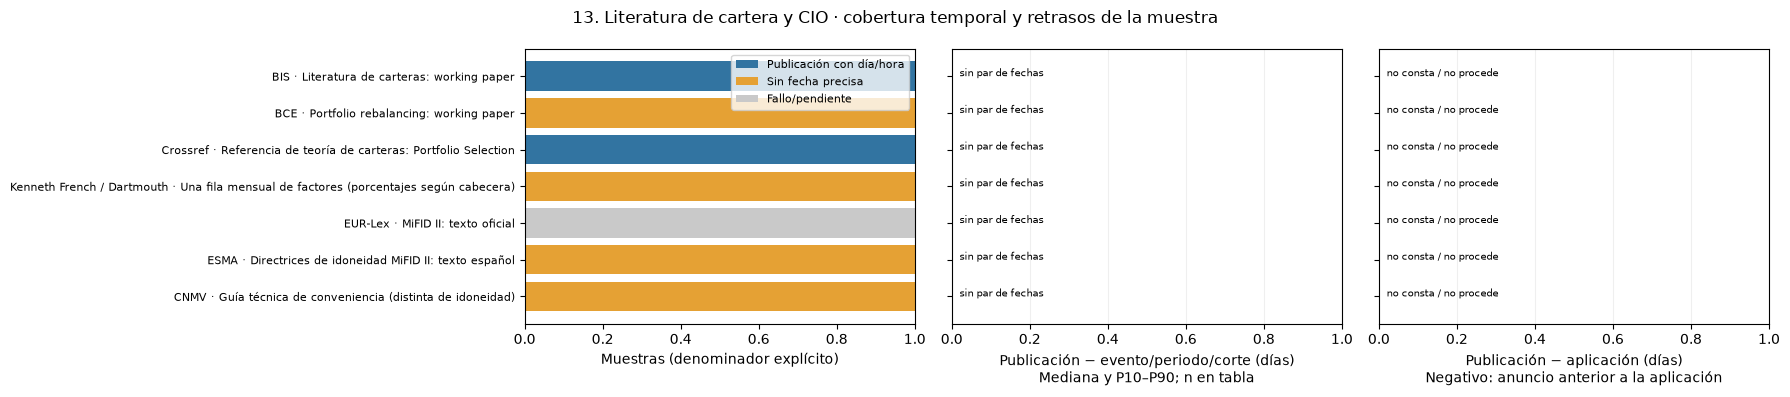

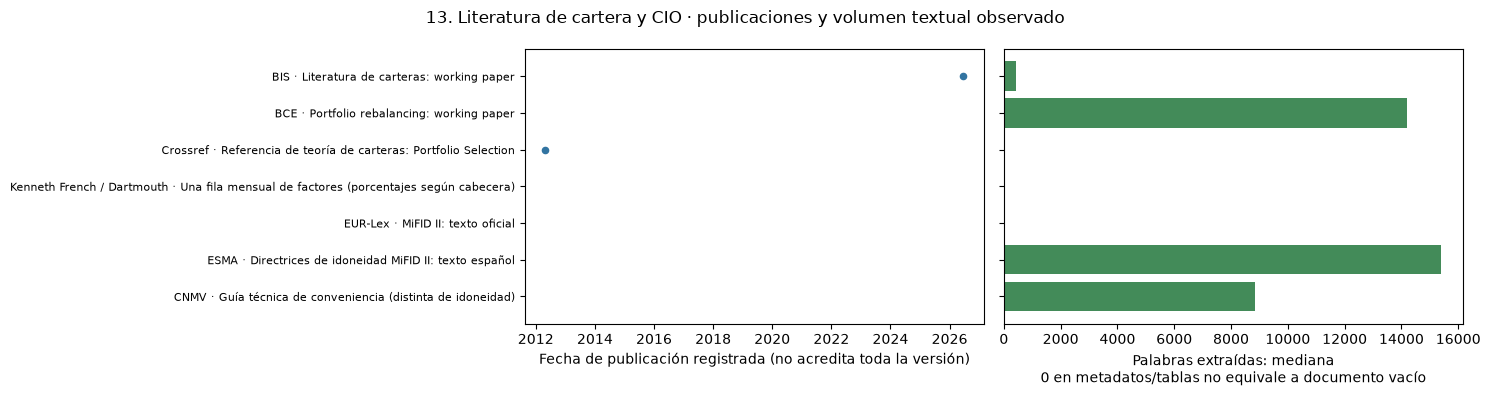

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
4,EUR-Lex,MiFID II: texto oficial,PENDIENTE,Respuesta vacía: revisar el enlace oficial,https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32014L0065


Ejemplo · Embracing carbon uncertainty in portfolio construction 
URL: https://www.bis.org/publ/work1362.htm 
Hash: f0d1ba00f18880e3edcf2f504d5b86007fc4bd26c78d6f61f01cd3220ccfb6f5
Embracing carbon uncertainty in portfolio construction

Focus

We study how to build sovereign bond portfolios that integrate financial and environmental considerations simultaneously. We introduce the concept of carbon returns, defined as the negative change in carbon emissions for a given country, paralleling the concept of financial returns. This allows us to apply traditional portfolio optimisation algorithms to both financial and carbon returns to guide portfolio choices.

Contribution

Most portfolio construction methods treat carbon emissions as deterministic paths, based on either historical data or forward-looking values tied to a specific scenario. That ignores uncertainty. Central to our approach is the introduction of carbon returns, treating the carbon footprint of individual countries as a rand

In [27]:
resumen_13 = mostrar_apartado(sonda, 13, '13. Literatura de cartera y CIO')

## 14. La literatura llega tarde

<a id="literatura-tarde"></a>

**Elección:** construir una auditoría de disponibilidad por versión. Esta tarjeta describe un análisis derivado, no un proveedor adicional del que descargar un corpus ya terminado.

**Prioridad actual:** conservar fechas y versiones durante la ingesta, pero posponer esta auditoría detallada hasta que se necesite un estudio histórico. Un paper posterior a una crisis puede aportar mucho a la biblioteca actual de los agentes.

| Evidencia necesaria | Fuente de mayor calidad | ¿Gratis? | Qué registrar |
|---|---|---|---|
| Primera versión pública de un preprint | Historial de versiones en [arXiv](https://arxiv.org/) o ficha original [SSRN](https://www.ssrn.com/) | Metadatos públicos; acceso concreto según portal | Identificador, versión y fecha pública respaldada |
| Publicación anticipada/editorial | Ficha del editor y [Crossref](https://www.crossref.org/documentation/retrieve-metadata/rest-api/) | Metadatos normalmente gratuitos; texto puede ser de pago | Online first, publicación formal y fuente de cada fecha |
| Copia previa autorizada | Repositorio institucional del autor; [Unpaywall](https://unpaywall.org/api/v2) ayuda a localizarla | Copias abiertas gratuitas cuando existen | Fecha de depósito y de apertura pública, que pueden ser distintas |
| Recuento y retraso frente a una crisis | Cálculo propio con corpus, versiones y fecha de corte explícitos | Fuentes anteriores; coste de procesamiento aparte | Incluido/excluido/incierto y razón verificable |

**Regla:** incluir solo la versión cuya disponibilidad pública anterior o igual al corte esté respaldada por evidencia. Una copia encontrada hoy no prueba que pudiera descargarse entonces. Si falta la fecha, marcar “incierta” y excluir de la evaluación histórica estricta hasta resolverla; no inventar un retraso medio.

Para comprobar “18 de 77 disponibles el 15-09-2008”, primero necesitamos los 77 identificadores y su historial. Tampoco se ha verificado el “+1,6 años” de la imagen. Informar denominador, tratamiento de versiones y casos inciertos antes de presentar esos valores como resultado.

### Sonda: adquisición y mediciones

**Medición específica.** Se usa el corte ilustrativo **15 de septiembre de 2008** como referencia en el retraso de publicación. Los valores negativos indican publicaciones anteriores al corte; los positivos, posteriores. La tabla incluye evidencia y estado de cada versión; un paper anterior puede quedar excluido si no se acredita su texto. No se reproducen «18 de 77» ni «+1,6 años» sin los identificadores y el historial del corpus completo.

In [28]:
inventario_14 = sonda.inventario(14)
display(inventario_14[["fuente", "tipo", "adaptador"]])
muestra_14 = sonda.ejecutar(14)

,fuente,tipo,adaptador
0,arXiv,Primera fecha pública y actualización del preprint,arxiv
1,Crossref,Fechas editoriales frente a fechas de registro,crossref
2,SSRN,Ficha original: buscar Posted / Last revised,documento
3,Unpaywall,Ubicación de copia abierta,unpaywall


4 intentos · 2 muestras obtenidas. La cobertura describe la muestra; no el archivo histórico completo.


C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\src\macro_riesgo\sonda\analysis.py:106: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cobertura(frame).round(2))


,fuente,tipo,intentos,OK,primera_muestra,ultima_muestra,sin_fecha_dia,n_retrasos,retraso_p10_d,retraso_mediana_d,retraso_p90_d,aplicacion_mediana_d,palabras_mediana,texto_completo,versiones_acreditadas,MB
0,arXiv,Primera fecha pública y actualización del preprint,1,1,2009-05-02 17:34:38+00:00,2009-05-02 17:34:38+00:00,0,1,229.0,229.0,229.0,NaN,15170.0,0,0,2.14
1,Crossref,Fechas editoriales frente a fechas de registro,1,1,NaT,NaT,1,0,NaN,NaN,NaN,NaN,0.0,0,0,0.00
2,SSRN,Ficha original: buscar Posted / Last revised,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00
3,Unpaywall,Ubicación de copia abierta,1,0,NaT,NaT,0,0,NaN,NaN,NaN,NaN,NaN,0,0,0.00


,fuente,tipo,estado,fecha_evento,fecha_publicacion,precision_publicacion,fecha_aplicacion,retraso_evento_dias,retraso_aplicacion_dias,evidencia_publicacion,estado_historico,url
0,arXiv,Primera fecha pública y actualización del preprint,OK,2008-09-15,2009-05-02T17:34:38+00:00,hora,None,229.0,NaN,Atom published y PDF fijado a 0905.0220v1,pendiente_versión,https://arxiv.org/pdf/0905.0220v1
1,Crossref,Fechas editoriales frente a fechas de registro,OK,2008-09-15,2008-03,mes,None,NaN,NaN,"Crossref published-online: fecha editorial, no apertura del PDF",pendiente_versión,https://api.crossref.org/works/10.3386/w13882
2,SSRN,Ficha original: buscar Posted / Last revised,ERROR_ACCESO,NaN,NaN,desconocida,None,NaN,NaN,,sin_muestra,https://papers.ssrn.com/sol3/papers.cfm?abstract_id=1106608
3,Unpaywall,Ubicación de copia abierta,PENDIENTE,NaN,NaN,desconocida,None,NaN,NaN,,sin_muestra,10.3386/w13882


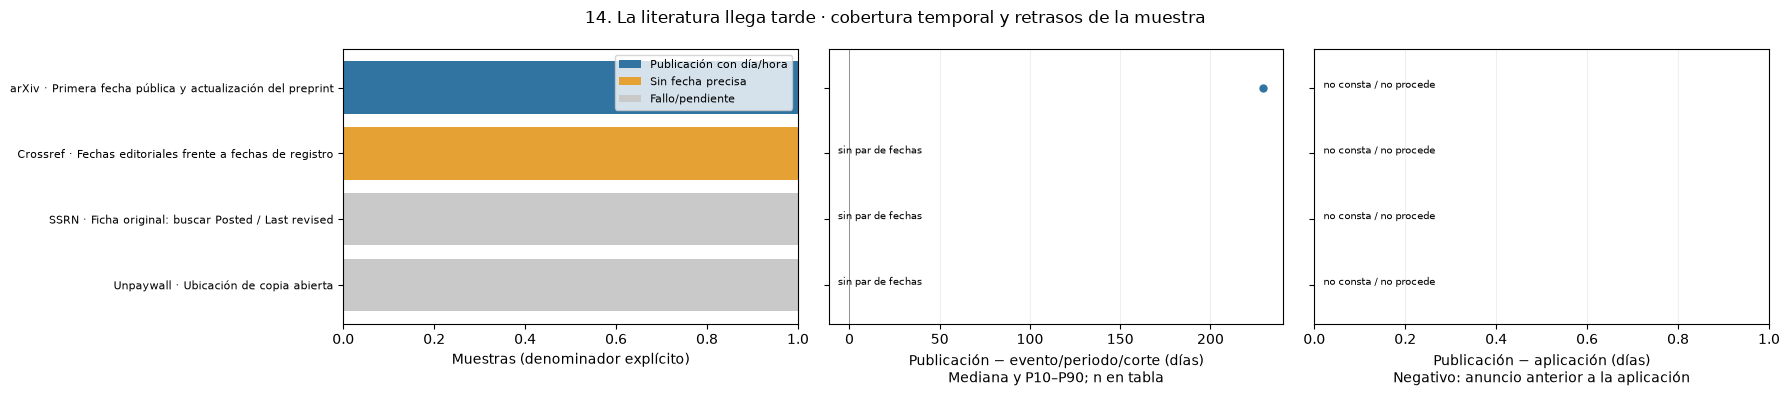

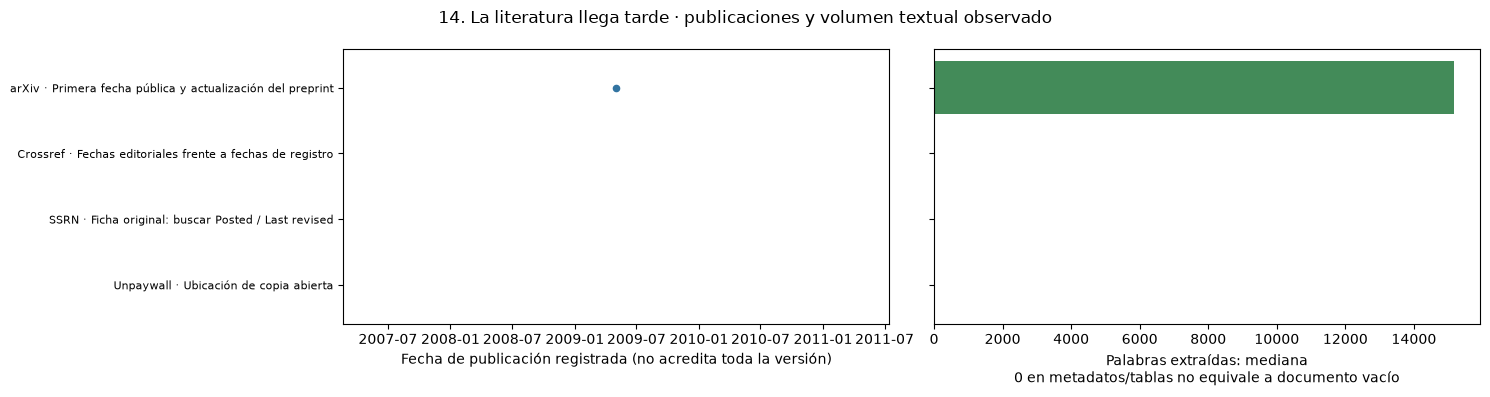

Fallos y pendientes de esta fuente:


,fuente,tipo,estado,error,url
2,SSRN,Ficha original: buscar Posted / Last revised,ERROR_ACCESO,HTTP 403; revisar acceso oficial,https://papers.ssrn.com/sol3/papers.cfm?abstract_id=1106608
3,Unpaywall,Ubicación de copia abierta,PENDIENTE,UNPAYWALL_EMAIL pendiente; completar variable de entorno con email real,10.3386/w13882


Ejemplo · Primera fecha pública y actualización del preprint 
URL: https://arxiv.org/pdf/0905.0220v1 
Hash: c3534fe0a4cfb873fdbad71281d7fb8c49ba835de2b55aa4e2ef63f4dbd6f237
arXiv:0905.0220v1  [q-fin.RM]  2 May 2009
Financial Bubbles, Real Estate bubbles,
Derivative Bubbles, and the Financial and
Economic Crisis
Didier Sornette and Ryan Woodard
Abstract The ﬁnancial crisis of 2008, which started with an initially well-deﬁned
epicenter focused on mortgage backed securities (MBS), has been cascading into a
global economic recession, whose increasing severity and uncertain duration has led
and is continuing to lead to massive losses and damage for billions of people. Heavy
central bank interventions and government spending progra ms have been launched
worldwide and especially in the USA and Europe, with the hope to unfreeze credit
and boltster consumption. Here, we present evidence and articulate a general frame-
work that allows one to diagnose the fundamental cause of the unfolding ﬁnanc

In [29]:
resumen_14 = mostrar_apartado(sonda, 14, '14. La literatura llega tarde')

## Volumen, exportación y resumen para el equipo

Todo se calcula desde los apartados ejecutados. Se conservan los fallos y las fechas ausentes. El tamaño cuenta originales únicos por hash **dentro de cada apartado**; una republicación puede aparecer en varios apartados y sus MB no deben sumarse como corpus deduplicado global. No se extrapola al universo sin inventario de documentos y una muestra representativa.

Los CSV de auditoría incluyen fuente, familia, fechas, precisión, evidencias, URL, hash, bytes, errores y política temporal. Los JSONL locales conservan además texto, fragmentos y filas de ejemplo. No hay subida a Cloudflare ni despliegue en esta sonda.

In [30]:
resumen_equipo = sonda.resumen()
display(resumen_equipo.round(2))
directorio_tablas = sonda.guardar_tablas()
print("Tablas de medición:", directorio_tablas)
print("Textos y fragmentos:", RAIZ / "data/local/sonda")
print("Originales:", RAIZ / "data/cache/sonda/objects")

,apartado,intentos,muestras_OK,fallos_pendientes,con_fecha,con_retraso_evento,con_aplicacion,versiones_acreditadas,MB_originales
0,1,16,16,0,12,6,0,0,6.38
1,2,7,7,0,7,3,1,0,0.87
2,3,18,18,0,12,6,0,0,10.98
3,4,10,10,0,9,0,0,0,1.34
4,5,47,42,5,19,3,3,0,71.56
5,6,5,3,2,0,0,0,0,10.36
6,7,6,5,1,3,0,0,0,0.31
7,8,18,18,0,12,0,0,0,20.07
8,9,7,6,1,6,0,0,0,0.84
9,10,3,0,3,0,0,0,0,0.00


Tablas de medición: C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\data\exports\sonda
Textos y fragmentos: C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\data\local\sonda
Originales: C:\Users\Fernando Dapena T\Desktop\Datos TFM\Bancos-centrales-riesgo-sistem-tico-y-literatura\data\cache\sonda\objects


## Limitaciones que quedan medidas

La sonda registra problemas de acceso, cambios de HTML, fechas incompletas y extracción parcial. El texto HTML puede incluir material accesorio y no se ha aplicado OCR a PDFs escaneados. La descarga del PDF completo puede ocupar más que sus páginas extraídas; las métricas separan bytes, páginas y texto completo.

La biblioteca de consulta general conserva estos textos y su contexto temporal. Para un backtest, deben acreditarse las versiones históricas de los portales, los vintages de tablas y la fecha de disponibilidad de traducciones y anotaciones. También hay que revisar el conocimiento futuro incorporado en cualquier modelo entrenado que produzca tono o resúmenes. Los gráficos muestran lo realmente medido y hacen visibles esas lagunas.